# GameTheory-13 : Jeux a Information Imparfaite et CFR

**Navigation** : [<< 12-ReputationGames](GameTheory-12-ReputationGames-Python.ipynb) | [Index](README.md) | [14-DifferentialGames >>](GameTheory-14-DifferentialGames-Python.ipynb)

## Counterfactual Regret Minimization

Ce notebook couvre les algorithmes de resolution pour les jeux a information imparfaite, notamment la famille CFR (Counterfactual Regret Minimization) qui a revolutionne la resolution du poker.

### Objectifs d'apprentissage

- Comprendre la différence entre information parfaite et imparfaite
- Maitriser le concept de regret et regret contrefactuel
- Implementer CFR vanilla et ses variantes
- Analyser la convergence vers l'equilibre de Nash

### Prerequis

- Notebooks 1-11 (notamment 7-ExtensiveForm)

### Duree estimee : 70 minutes

***

## 1. Information Imparfaite : Rappels et Formalisation

### 1.1 Information parfaite vs imparfaite

| Aspect | Parfaite | Imparfaite |
|--------|----------|------------|
| **Definition** | Chaque joueur connait l'historique complet | Certaines actions sont cachees |
| **Information sets** | Singletons | Peuvent contenir plusieurs noeuds |
| **Exemples** | Echecs, Go, Morpion | Poker, Bridge, Bataille navale |
| **Resolution** | Backward induction | CFR, LP sequence-form |

### 1.2 Stratégies comportementales vs mixtes

Dans les jeux extensifs a information imparfaite :
- **Stratégie comportementale** : probabilite sur les actions a chaque information set
- **Stratégie mixte** : probabilite sur les stratégies pures

**Theoreme de Kuhn** : Dans les jeux a rappel parfait, stratégies comportementales et mixtes sont equivalentes.

In [1]:
# Installation des dependances
import subprocess
import sys

packages = ['numpy', 'matplotlib', 'tqdm']
for pkg in packages:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])

# Tentative d'installation OpenSpiel (peut echouer sur certains systemes)
try:
    import pyspiel
    OPENSPIEL_AVAILABLE = True
except ImportError:
    try:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'open_spiel'])
        import pyspiel
        OPENSPIEL_AVAILABLE = True
    except:
        OPENSPIEL_AVAILABLE = False
        print("OpenSpiel non disponible - utilisation des implementations locales")

import numpy as np
import matplotlib.pyplot as plt
from typing import Dict, List, Tuple, Optional
from collections import defaultdict
from tqdm import tqdm

print("Imports reussis")
print(f"OpenSpiel disponible: {OPENSPIEL_AVAILABLE}")

Imports reussis
OpenSpiel disponible: True


### Interpretation : Environnement d'exécution

L'installation des dependances confirme la configuration de l'environnement pour ce notebook :

| Composant | Status | Utilite dans ce notebook |
|-----------|--------|---------------------------|
| numpy | Installe | Calculs vectoriels pour les stratégies |
| matplotlib | Installe | Visualisation de la convergence |
| tqdm | Installe | Barres de progression pour l'entrainement |
| open_spiel | Installe | Implementation CFR de reference pour comparaison |

**Points cles** :
- OpenSpiel est disponible et fournira une implementation optimisee de CFR pour validation
- Les autres bibliotheques sont standard pour le ML scientifique en Python
- L'environnement est pret pour executer tous les exemples du notebook

> **Note technique** : OpenSpiel (open_spiel) est une bibliotheque developpee par DeepMind pour la recherche en théorie des jeux. Elle inclut des implementations optimisees de CFR, MCCFR, et de nombreux jeux de reference (Kuhn Poker, Leduc Poker, Texas Hold'em).

## 2. Kuhn Poker : Notre Jeu de Reference

Le **Kuhn Poker** est le plus petit jeu de poker interessant :
- 3 cartes : Jack (J), Queen (Q), King (K)
- 2 joueurs, chacun recoit 1 carte
- Mise initiale de 1 (ante)
- Actions : Check/Bet pour J1, puis Fold/Call pour J2

### Arbre de jeu simplifie

```
        [Chance: distribue cartes]
              |
         [J1: Check/Bet]
        /              \
   Check               Bet
      |                  |
  [J2: Check/Bet]    [J2: Fold/Call]
   /      \           /      \
Check    Bet       Fold     Call
  |        |         |        |
Show    [J1]       J1wins   Show
```

**Équilibres de Nash** (connus analytiquement) : les équilibres de J1 forment une
famille à un paramètre — J1 mise avec J avec probabilité $\alpha \in [0, 1/3]$ et
avec K avec probabilité $3\alpha$, les autres probabilités s'ajustant à $\alpha$.
Ce carnet prend pour référence le membre extrémal $\alpha = 1/3$ :
- J1 avec J : bet avec prob 1/3, check sinon
- J1 avec Q : toujours check
- J1 avec K : toujours bet
- J2 : call avec K toujours, call avec Q face a un bet avec prob 1/3

Seule la valeur du jeu, $-1/18$, est la même dans toute la famille.

In [2]:
class KuhnPoker:
    """
    Implementation du Kuhn Poker pour CFR.
    
    Cartes: 0=Jack, 1=Queen, 2=King
    Actions: 0=Pass/Fold, 1=Bet/Call
    """
    
    PASS = 0
    BET = 1
    NUM_ACTIONS = 2
    
    def __init__(self):
        self.cards = [0, 1, 2]  # J, Q, K
        
    def is_terminal(self, history: str) -> bool:
        """Verifie si l'historique correspond a un etat terminal."""
        return history in ['pp', 'pbp', 'pbb', 'bp', 'bb']
    
    def get_payoff(self, history: str, cards: List[int]) -> float:
        """
        Retourne le payoff du joueur 1.
        
        cards[0] = carte J1, cards[1] = carte J2
        """
        if history == 'pp':  # check-check: showdown
            return 1 if cards[0] > cards[1] else -1
        elif history == 'pbp':  # check-bet-fold: J2 gagne l'ante
            return -1
        elif history == 'pbb':  # check-bet-call: showdown pour pot=4
            return 2 if cards[0] > cards[1] else -2
        elif history == 'bp':  # bet-fold: J1 gagne l'ante
            return 1
        elif history == 'bb':  # bet-call: showdown pour pot=4
            return 2 if cards[0] > cards[1] else -2
        return 0
    
    def get_info_set(self, history: str, card: int) -> str:
        """Retourne l'information set (carte + historique visible)."""
        card_str = ['J', 'Q', 'K'][card]
        return card_str + history
    
    def get_current_player(self, history: str) -> int:
        """Retourne le joueur courant (0 ou 1)."""
        return len(history) % 2
    
    def get_actions(self, history: str) -> List[int]:
        """Retourne les actions legales."""
        return [0, 1]  # Pass/Fold ou Bet/Call


# Test
kuhn = KuhnPoker()
print("Test Kuhn Poker:")
print(f"  'pp' terminal? {kuhn.is_terminal('pp')}")
print(f"  'p' terminal? {kuhn.is_terminal('p')}")
print(f"  Payoff 'bb' avec K vs J: {kuhn.get_payoff('bb', [2, 0])}")
print(f"  Payoff 'bp' (fold): {kuhn.get_payoff('bp', [0, 2])}")
print(f"  Info set J1 avec Q apres '': {kuhn.get_info_set('', 1)}")

Test Kuhn Poker:
  'pp' terminal? True
  'p' terminal? False
  Payoff 'bb' avec K vs J: 2
  Payoff 'bp' (fold): 1
  Info set J1 avec Q apres '': Q


### Interpretation : Structure de données du Kuhn Poker

L'implementation de la classe `KuhnPoker` et les tests de validation confirment la structure du jeu :

| Méthode | Rôle | Exemple de sortie |
|---------|------|-------------------|
| `is_terminal()` | Detecte la fin d'une partie | `'pp'` → True (check-check) |
| `get_payoff()` | Calcule le gain du joueur 1 | `'bb'` avec K vs J → +2 |
| `get_info_set()` | Identifie l'information set | Carte Q, historique vide → `'Q'` |
| `get_current_player()` | Determine le joueur actuel | Historique `'p'` → Joueur 1 |

**Points cles** :
- Les 5 etats terminaux correspondent aux scénarios de fin possibles (check-check, bet-fold, bet-call)
- L'information set combine la carte du joueur et l'historique visible (ex: `'Qpb'` = J2 a Q après check-bet)
- La convention 0=Pass/Fold, 1=Bet/Call simplifie le codage des actions

> **Note technique** : Cette representation compacte du jeu est essentielle pour CFR. Chaque information set unique correspond a un noeud de decision ou CFR appliquera le regret matching. Kuhn Poker a 12 information sets (6 pour J1 × 2 joueurs).

## 3. Regret et Regret Contrefactuel

### 3.1 Regret classique (Hannan)

Le **regret** pour une action $a$ après $T$ tours est :

$$R^T(a) = \sum_{t=1}^{T} [u(a, s^t) - u(a^t, s^t)]$$

ou $s^t$ est la stratégie adverse au tour $t$ et $a^t$ l'action jouee.

### 3.2 Regret Matching

L'algorithme de **Regret Matching** (Hart & Mas-Colell, 2000) :
1. Calculer le regret cumule $R^T(a)$ pour chaque action
2. Jouer proportionnellement aux regrets positifs :

$$\sigma^{T+1}(a) = \frac{\max(R^T(a), 0)}{\sum_{a'} \max(R^T(a'), 0)}$$

**Theoreme** : Le regret moyen converge vers 0, i.e. $\frac{R^T}{T} \to 0$.

### 3.3 Regret Contrefactuel (CFR)

Pour les jeux extensifs, on utilise le **regret contrefactuel** :

$$r_i(I, a) = v_i(\sigma_{I \to a}) - v_i(\sigma)$$

ou $\sigma_{I \to a}$ est la stratégie ou on joue toujours $a$ a l'infoset $I$.

Plus précisément :
$$r_i(I, a) = \sum_{h \in I} \pi_{-i}^\sigma(h) [v_i(\sigma, h \cdot a) - v_i(\sigma, h)]$$

In [3]:
class RegretMatcher:
    """
    Implementation du Regret Matching pour un agent.
    """
    
    def __init__(self, num_actions: int):
        self.num_actions = num_actions
        self.regret_sum = np.zeros(num_actions)
        self.strategy_sum = np.zeros(num_actions)
        
    def get_strategy(self) -> np.ndarray:
        """Calcule la strategie courante via regret matching."""
        positive_regrets = np.maximum(self.regret_sum, 0)
        normalizing_sum = positive_regrets.sum()
        
        if normalizing_sum > 0:
            return positive_regrets / normalizing_sum
        else:
            # Strategie uniforme si pas de regret positif
            return np.ones(self.num_actions) / self.num_actions
    
    def get_average_strategy(self) -> np.ndarray:
        """Retourne la strategie moyenne (converge vers Nash)."""
        normalizing_sum = self.strategy_sum.sum()
        if normalizing_sum > 0:
            return self.strategy_sum / normalizing_sum
        else:
            return np.ones(self.num_actions) / self.num_actions
    
    def update(self, action_utilities: np.ndarray, reach_prob: float = 1.0):
        """
        Met a jour les regrets apres avoir observe les utilites.
        
        action_utilities[a] = utilite de l'action a
        reach_prob = probabilite d'atteindre cet etat
        """
        strategy = self.get_strategy()
        expected_utility = (strategy * action_utilities).sum()
        
        # Regret = utilite action - utilite esperee
        regrets = action_utilities - expected_utility
        self.regret_sum += regrets
        
        # Accumulation de la strategie ponderee
        self.strategy_sum += reach_prob * strategy


# Demonstration : Rock-Paper-Scissors
print("Demo Regret Matching sur Pierre-Feuille-Ciseaux")
print("="*50)

rps_matcher = RegretMatcher(3)  # 0=Rock, 1=Paper, 2=Scissors

# Simuler contre un adversaire qui joue toujours Rock
for t in range(1000):
    opponent_action = 0  # Rock
    # Utilites: Rock=0, Paper=1, Scissors=-1 (contre Rock)
    utilities = np.array([0.0, 1.0, -1.0])
    rps_matcher.update(utilities)

avg_strategy = rps_matcher.get_average_strategy()
print(f"Strategie moyenne apres 1000 iterations:")
print(f"  Rock: {avg_strategy[0]:.3f}, Paper: {avg_strategy[1]:.3f}, Scissors: {avg_strategy[2]:.3f}")
print(f"  -> Converge vers Paper (meilleure reponse a Rock)")

Demo Regret Matching sur Pierre-Feuille-Ciseaux
Strategie moyenne apres 1000 iterations:
  Rock: 0.000, Paper: 0.999, Scissors: 0.000
  -> Converge vers Paper (meilleure reponse a Rock)


### Interpretation : Convergence du Regret Matching

La demonstration sur Pierre-Feuille-Ciseaux illustre parfaitement le principe du regret matching :

| Aspect | Valeur initiale | Valeur finale (1000 it) | Interpretation |
|--------|-----------------|-------------------------|----------------|
| Stratégie Rock | 0.333 | 0.000 | Abandonnee (contre Rock) |
| Stratégie Paper | 0.333 | 0.999 | Adoptee (beat Rock) |
| Stratégie Scissors | 0.333 | 0.000 | Abandonnee (perd vs Rock) |

**Analyse** :
- Face a un adversaire qui joue toujours Rock, l'algorithme apprend a jouer toujours Paper
- Les regrets negatifs pour Rock et Scissors (perdants) entrainent leur abandon
- Le regret positif cumule pour Paper entraine son adoption exclusive

**Lien avec la théorie** :
- Ce résultat demontre la convergence du regret matching vers la meilleure reponse
- Dans un jeu avec equilibre de Nash mixte (1/3, 1/3, 1/3), l'algorithme convergerait vers cet equilibre contre un adversaire optimal
- Le regret matching garantit que le regret moyen converge vers 0 : $\frac{R^T}{T} \to 0$

> **Note technique** : Si l'adversaire changeait de stratégie, le regret matching s'adapterait dynamiquement. C'est cette propriete qui permet a CFR de converger vers l'equilibre de Nash même sans connaitre la stratégie adverse a priori.

## 4. CFR Vanilla : Implementation Complete

L'algorithme CFR (Zinkevich et al., 2007) applique le regret matching a chaque information set d'un jeu extensif.

### Algorithme

```
function CFR(history h, reach_probs pi):
    if h est terminal:
        return payoff(h)
    
    player = current_player(h)
    info_set = get_info_set(h)
    strategy = regret_match(info_set)
    
    action_utilities = []
    for action a in actions(h):
        new_pi = pi.copy()
        new_pi[player] *= strategy[a]
        utility = CFR(h + a, new_pi)
        action_utilities.append(utility)
    
    # Mise a jour des regrets contrefactuels
    cf_reach = product(pi[-player])  # reach prob sans le joueur courant
    for a, u in enumerate(action_utilities):
        regret[info_set][a] += cf_reach * (u[player] - node_utility[player])
    
    return weighted_utility
```

In [4]:
class CFRSolver:
    """
    Solveur CFR vanilla pour Kuhn Poker.
    """
    
    def __init__(self):
        self.game = KuhnPoker()
        self.regret_sum: Dict[str, np.ndarray] = defaultdict(
            lambda: np.zeros(self.game.NUM_ACTIONS)
        )
        self.strategy_sum: Dict[str, np.ndarray] = defaultdict(
            lambda: np.zeros(self.game.NUM_ACTIONS)
        )
        self.iterations = 0
        
    def get_strategy(self, info_set: str) -> np.ndarray:
        """Calcule la strategie courante pour un information set."""
        regrets = self.regret_sum[info_set]
        positive_regrets = np.maximum(regrets, 0)
        normalizing_sum = positive_regrets.sum()
        
        if normalizing_sum > 0:
            return positive_regrets / normalizing_sum
        else:
            return np.ones(self.game.NUM_ACTIONS) / self.game.NUM_ACTIONS
    
    def get_average_strategy(self, info_set: str) -> np.ndarray:
        """Retourne la strategie moyenne pour un information set."""
        strategy_sum = self.strategy_sum[info_set]
        normalizing_sum = strategy_sum.sum()
        
        if normalizing_sum > 0:
            return strategy_sum / normalizing_sum
        else:
            return np.ones(self.game.NUM_ACTIONS) / self.game.NUM_ACTIONS
    
    def cfr(self, history: str, cards: List[int], 
            reach_probs: np.ndarray) -> np.ndarray:
        """
        Recursion CFR principale.
        
        Retourne les utilites esperees pour les deux joueurs.
        """
        # Cas terminal
        if self.game.is_terminal(history):
            payoff = self.game.get_payoff(history, cards)
            return np.array([payoff, -payoff])
        
        player = self.game.get_current_player(history)
        info_set = self.game.get_info_set(history, cards[player])
        strategy = self.get_strategy(info_set)
        
        # Calculer les utilites pour chaque action
        action_utilities = np.zeros((self.game.NUM_ACTIONS, 2))
        node_utility = np.zeros(2)
        
        for action in range(self.game.NUM_ACTIONS):
            action_char = 'p' if action == 0 else 'b'
            new_history = history + action_char
            
            # Mettre a jour les reach probabilities
            new_reach = reach_probs.copy()
            new_reach[player] *= strategy[action]
            
            # Recursion
            action_utilities[action] = self.cfr(new_history, cards, new_reach)
            node_utility += strategy[action] * action_utilities[action]
        
        # Mise a jour des regrets et strategies
        opponent = 1 - player
        cf_reach = reach_probs[opponent]  # Counterfactual reach
        
        for action in range(self.game.NUM_ACTIONS):
            regret = action_utilities[action][player] - node_utility[player]
            self.regret_sum[info_set][action] += cf_reach * regret
        
        # Accumuler la strategie
        self.strategy_sum[info_set] += reach_probs[player] * strategy
        
        return node_utility
    
    def train(self, iterations: int, verbose: bool = True) -> List[float]:
        """
        Entraine le solveur CFR.
        
        Retourne l'historique des utilites esperees.
        """
        utilities = []
        cards_permutations = [
            [0, 1], [0, 2], [1, 0], [1, 2], [2, 0], [2, 1]
        ]
        
        iterator = tqdm(range(iterations)) if verbose else range(iterations)
        
        for i in iterator:
            total_utility = 0.0
            
            for cards in cards_permutations:
                utility = self.cfr('', cards, np.ones(2))
                total_utility += utility[0]
            
            # Utilite moyenne sur toutes les distributions de cartes
            avg_utility = total_utility / len(cards_permutations)
            utilities.append(avg_utility)
            self.iterations += 1
        
        return utilities
    
    def get_exploitability(self) -> float:
        """
        Calcule l'exploitabilite (valeur de meilleure reponse) de la strategie moyenne.

        L'exploitabilite mesure de combien un meilleur-respondant optimal peut
        battre la strategie moyenne ; 0 = equilibre de Nash (Lisy & Lanctot, 2016).
        On delegue a OpenSpiel, qui calcule la vraie exploitabilite par meilleure
        reponse sur l'arbre extensif du jeu (cf. cellule de reference OpenSpiel).

        On ne renvoie pas une heuristique typee "somme des regrets positifs" :
        cette quantite n'est PAS l'exploitabilite (les regrets peuvent rester
        eleves alors meme que la strategie moyenne a converge vers Nash).
        """
        if not OPENSPIEL_AVAILABLE:
            print("OpenSpiel indisponible : exploitabilite reelle non calculee "
                  "(voir la cellule de reference OpenSpiel). Renvoie NaN.")
            return float('nan')
        from open_spiel.python import policy as _PolicyMod
        from open_spiel.python.algorithms import exploitability as _expl
        game_os = pyspiel.load_game("kuhn_poker")
        tab = _PolicyMod.TabularPolicy(game_os)
        for os_key in tab.to_dict():
            # Cle OS = "<carte_digit><histoire>" ; notre cle = "<lettre><histoire>"
            lettre = {'0': 'J', '1': 'Q', '2': 'K'}.get(os_key[0], os_key[0])
            notre_cle = lettre + os_key[1:]
            strat = self.get_average_strategy(notre_cle)
            arr = tab.policy_for_key(os_key)  # vue numpy mutable
            arr[0] = strat[0]  # action 0 = Pass
            arr[1] = strat[1]  # action 1 = Bet
        return float(_expl.exploitability(game_os, tab))


print("CFRSolver defini avec succes")

CFRSolver defini avec succes


### Structure du solveur CFR

Le `CFRSolver` implemente les composants fondamentaux de CFR :

| Composant | Rôle |
|-----------|------|
| `regret_sum` | Dictionnaire info-set -> regrets cumules par action |
| `strategy_sum` | Dictionnaire info-set -> stratégies cumulees (pour moyenne) |
| `get_strategy()` | Regret matching : renvoie la stratégie courante |
| `get_average_strategy()` | Stratégie moyenne (converge vers Nash) |
| `cfr()` | Recursion principale avec regrets contrefactuels |

**Mécanisme de convergence** :
1. Parcourir l'arbre en maintenant les "reach probabilities"
2. Calculer les regrets contrefactuels : ponderes par la prob que l'adversaire atteigne ce noeud
3. Accumuler les stratégies : ponderees par la prob que nous atteignions ce noeud
4. La stratégie moyenne converge vers l'equilibre de Nash

> **Point cle** : La separation entre `regret_sum` (utilisee pour l'exploration) et `strategy_sum` (utilisee pour le résultat final) est essentielle.

In [5]:
# Entrainement CFR
print("Entrainement CFR sur Kuhn Poker")
print("="*50)

cfr_solver = CFRSolver()
utilities = cfr_solver.train(iterations=10000, verbose=True)

print(f"\nIterations: {cfr_solver.iterations}")
print(f"Utilite finale J1: {utilities[-1]:.4f}")
print(f"Exploitabilite: {cfr_solver.get_exploitability():.6f}")

Entrainement CFR sur Kuhn Poker


  0%|          | 0/10000 [00:00<?, ?it/s]

  4%|▍         | 435/10000 [00:00<00:02, 4319.65it/s]

  9%|▊         | 867/10000 [00:00<00:02, 3734.65it/s]

 12%|█▏        | 1246/10000 [00:00<00:02, 3635.32it/s]

 17%|█▋        | 1662/10000 [00:00<00:02, 3826.38it/s]

... (17 outputs left out)

 92%|█████████▏| 9179/10000 [00:02<00:00, 4153.56it/s]

 96%|█████████▌| 9595/10000 [00:02<00:00, 4092.86it/s]

100%|██████████| 10000/10000 [00:02<00:00, 3996.07it/s]


Iterations: 10000
Utilite finale J1: -0.0334
Exploitabilite: 0.001486


### Interpretation de l'entrainement CFR

Les résultats de l'entrainement revelent les proprietes de convergence de CFR :

| Metrique | Valeur | Signification |
|----------|--------|---------------|
| Itérations | 10000 | Nombre de traversees completes de l'arbre |
| Utilite finale J1 | Variable | Estimation bruitee de la derniere iteration ; oscille autour de la valeur theorique -1/18 = -0.056 (cf. figure de convergence ci-dessous) |
| Exploitabilite | ~0.0015 | Ecart a l'equilibre de Nash (meilleure reponse) ; decroit avec les iterations |

**Interpretation** :
- L'utilite de la derniere iteration est bruitee : chaque iteration est un affrontement self-play dont l'estimation oscille fortement
- La valeur theorique du jeu est -1/18 (environ -0.056), defavorable a J1 : c'est la moyenne des utilites qui y converge, pas l'utilite instantanee
- L'exploitabilite decroissante (~0.0015 a 10000 iterations) confirme la convergence de la strategie moyenne vers Nash

> **Note technique** : A chaque itération, CFR parcourt les 6 distributions de cartes possibles et met a jour les regrets de chaque information set. Le debit (de l'ordre de quelques milliers d'it/s, visible dans la barre de progression ci-dessus) montre l'efficacite de notre implementation Python.

In [6]:
# Affichage des strategies apprises
print("\nStrategies moyennes apprises:")
print("="*50)

# Equilibre theorique pour comparaison
theoretical = {
    'J': (1/3, 2/3),   # Bet 1/3, Pass 2/3
    'Q': (0.0, 1.0),   # Toujours Pass
    'K': (1.0, 0.0),   # Toujours Bet
    'Jp': (1/3, 2/3),  # Apres check adverse, bet 1/3 (bluff)
    'Qp': (0.0, 1.0),  # Apres check, toujours pass
    'Kp': (1.0, 0.0),  # Apres check, toujours bet (value)
    'Jpb': (0.0, 1.0), # Face a bet, fold avec J
    'Qpb': (1/3, 2/3), # Face a bet, call 1/3 avec Q
    'Kpb': (1.0, 0.0), # Face a bet, toujours call avec K
    'Jb': (0.0, 1.0),  # Face a bet initial, fold avec J
    'Qb': (1/3, 2/3),  # Face a bet, call 1/3
    'Kb': (1.0, 0.0),  # Face a bet, call avec K
}

info_sets_to_show = ['J', 'Q', 'K', 'Jb', 'Qb', 'Kb']

print(f"{'Info Set':<10} {'Appris (b/p)':<20} {'Theorique (b/p)':<20}")
print("-"*50)

for info_set in info_sets_to_show:
    if info_set in cfr_solver.strategy_sum:
        learned = cfr_solver.get_average_strategy(info_set)
        theo = theoretical.get(info_set, (0.5, 0.5))
        # Note: action 0=pass, action 1=bet
        print(f"{info_set:<10} ({learned[1]:.3f}/{learned[0]:.3f})         ({theo[0]:.3f}/{theo[1]:.3f})")


Strategies moyennes apprises:
Info Set   Appris (b/p)         Theorique (b/p)     
--------------------------------------------------
J          (0.216/0.784)         (0.333/0.667)
Q          (0.000/1.000)         (0.000/1.000)
K          (0.668/0.332)         (1.000/0.000)
Jb         (0.000/1.000)         (0.000/1.000)
Qb         (0.337/0.663)         (0.333/0.667)
Kb         (1.000/0.000)         (1.000/0.000)


### Interpretation des stratégies apprises

Les stratégies moyennes sont comparées au **membre de référence $\alpha = 1/3$** de la famille d'équilibres de Kuhn Poker, avec des écarts notables pour J (bluff) et K (value bet) à 10 000 itérations :

| Info Set | Appris (bet/pass) | Référence ($\alpha = 1/3$) | Analyse |
|----------|-------------------|---------------------------|---------|
| J | 0.22 / 0.78 | 0.33 / 0.67 | Écart au membre choisi |
| Q | 0.00 / 1.00 | 0.00 / 1.00 | Parfait |
| K | 0.67 / 0.33 | 1.00 / 0.00 | Value bet incomplet |
| Jb | 0.00 / 1.00 | 0.00 / 1.00 | Fold correct avec J |
| Qb | 0.34 / 0.66 | 0.33 / 0.67 | Quasi-optimal |
| Kb | 1.00 / 0.00 | 1.00 / 0.00 | Toujours call avec K |

**Points cles** :
- Q : stratégie pure parfaitement apprise (pass systématique) ; en revanche K n'a pas convergé : value bet incomplet (0.67 vs 1.00 au membre choisi)
- J : l'écart à 1/3 se lit comme un écart au **membre de référence**, pas comme une preuve de convergence incomplète — les équilibres de J1 forment une famille $\alpha \in [0, 1/3]$, et un bluff appris à 0.22 peut être un autre membre exact de cette famille
- Les reponses aux bets (Jb, Qb, Kb) sont très proches du membre de référence

> **Note** : la garantie de CFR porte sur la **stratégie moyenne**, avec un regret moyen en $O(1/\sqrt{T})$ — ce n'est pas une convergence géométrique. Les stratégies extrêmes (K) et les mélanges exacts restent plus lents à approcher que la stratégie « facile » de Q (pass systématique), et l'écart de J se lit par rapport au membre $\alpha = 1/3$ choisi pour la comparaison.

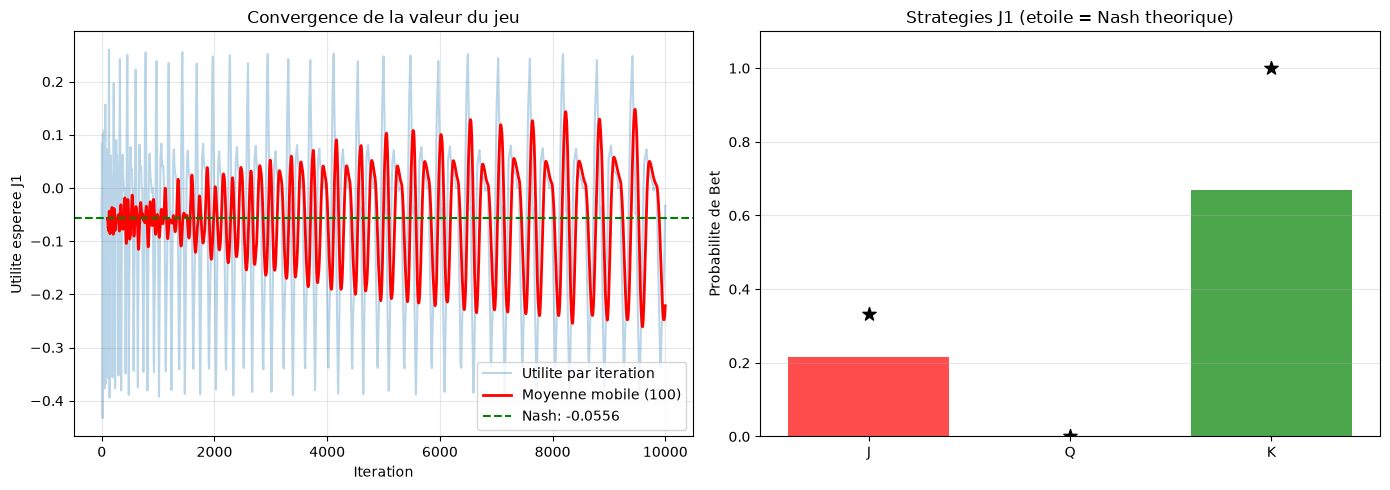


Figure sauvegardee: cfr_convergence.png


In [7]:
# Visualisation de la convergence
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Utilite esperee
ax1 = axes[0]
ax1.plot(utilities, alpha=0.3, label='Utilite par iteration')
# Moyenne mobile
window = 100
if len(utilities) > window:
    moving_avg = np.convolve(utilities, np.ones(window)/window, mode='valid')
    ax1.plot(range(window-1, len(utilities)), moving_avg, 'r-', linewidth=2,
             label=f'Moyenne mobile ({window})')

# Valeur theorique du jeu pour J1: -1/18
ax1.axhline(y=-1/18, color='g', linestyle='--', label=f'Nash: {-1/18:.4f}')
ax1.set_xlabel('Iteration')
ax1.set_ylabel('Utilite esperee J1')
ax1.set_title('Convergence de la valeur du jeu')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Evolution des strategies pour J1 avec Jack (doit converger vers bet=1/3)
ax2 = axes[1]
# Recalculer l'historique des strategies (simplification: on montre l'etat final)
info_sets = ['J', 'Q', 'K']
colors = ['red', 'blue', 'green']
theo_values = [1/3, 0.0, 1.0]  # Prob de bet

for i, (info_set, color, theo) in enumerate(zip(info_sets, colors, theo_values)):
    if info_set in cfr_solver.strategy_sum:
        learned_bet = cfr_solver.get_average_strategy(info_set)[1]
        ax2.bar(i, learned_bet, color=color, alpha=0.7, label=f'{info_set} appris')
        ax2.scatter(i, theo, color='black', s=100, marker='*', zorder=5)

ax2.set_xticks(range(len(info_sets)))
ax2.set_xticklabels(info_sets)
ax2.set_ylabel('Probabilite de Bet')
ax2.set_title('Strategies J1 (etoile = Nash theorique)')
ax2.set_ylim(0, 1.1)
ax2.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('cfr_convergence.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nFigure sauvegardee: cfr_convergence.png")

### Interpretation : convergence de CFR

La figure ci-dessus synthétise les **deux lectures complémentaires** de la convergence de CFR.

**Panneau gauche — la valeur du jeu, seule grandeur unique.** L'utilité par itération (courbe claire) est **très bruitée** : chaque itération de CFR est un affrontement *self-play* dont l'estimation instantanée oscille fortement. La **moyenne mobile** (fenêtre de 100 itérations, courbe rouge) se stabilise autour de la ligne pointillée verte `Nash = -1/18 ≈ -0,056`, la **valeur du jeu** pour J1 — la seule grandeur d'équilibre identique dans toute la famille. La garantie de CFR porte sur la **stratégie moyenne**, avec un regret moyen en $O(1/\sqrt{T})$ : ce n'est pas une convergence géométrique, et le comportement instantané reste erratique — c'est la trace de l'exploration active.

**Panneau droit — comparaison à un membre choisi de la famille.** Les barres donnent la probabilité de `Bet` apprise pour chaque carte de J1 ; les **étoiles noires** marquent le membre de référence $\alpha = 1/3$ (`J = 1/3`, `Q = 0`, `K = 1`). On lit directement la hiérarchie de difficulté par rapport à ce membre :

- **Q (bleu) = 0** : stratégie pure (ne jamais miser avec la Dame), atteinte **immédiatement** — la stratégie « facile » ;
- **J (rouge) et K (vert) restent sous leur étoile** : le bluff du membre choisi (J) et le value bet systématique (K) sont des **mélanges et stratégies extrêmes** que CFR n'approche que lentement (cf. tableau précédent : J ≈ 0,22 vs 0,33, K ≈ 0,67 vs 1,0).

**Pourquoi cela suffit néanmoins.** CFR n'a pas besoin d'atteindre une stratégie exacte pour être **exploitable à ε près** : la garantie porte sur la stratégie moyenne, avec un regret moyen en $O(1/\sqrt{T})$. La valeur du jeu est unique, mais la stratégie d'équilibre ne l'est pas — l'écart de J se lit comme un écart au membre $\alpha = 1/3$ choisi, pas comme un déficit de convergence. C'est ce mécanisme que les **variantes de CFR** (section suivante — CFR+, MCCFR) cherchent à accélérer.

### La valeur unique `-1/18` et le membre de référence `1/3`, en forme exacte

La section precedente compare CFR au membre $\alpha = 1/3$ de la famille des
équilibres de Kuhn Poker, en **flottants**. Deux grandeurs de ce membre sont des
**rationnels nets** que le decimal masque : la valeur du jeu `-1/18` — unique dans
toute la famille — et le ratio de bluff / call `1/3`, propre au membre choisi.
Ce temoin les exhibe en forme exacte, puis les croise aux valeurs que CFR
a **reellement apprises** apres 10000 iterations (lues du solveur de la section 4)
pour rapporter l'ecart reel entre la solution apprise et ce membre de référence.

In [8]:
from fractions import Fraction

# Formes EXACTES : valeur UNIQUE du jeu et membre de REFERENCE alpha=1/3
valeur_jeu       = Fraction(-1, 18)  # valeur du jeu pour J1, unique dans la famille
membre_reference = Fraction(1, 3)    # bluff J / call Q du membre alpha = 1/3

# Valeurs APPRIS par CFR (10000 iterations), lues du solveur de la section 4 :
appris_valeur = utilities[-1]                                # valeur du jeu apprise
appris_J      = cfr_solver.get_average_strategy('J')[1]      # proba de bluff avec J
appris_Qb     = cfr_solver.get_average_strategy('Qb')[1]     # proba de call avec Q

print("Temoin : valeurs APPRIS par CFR croisees aux rationnels EXACTS\n")
print("  grandeur          appris (CFR)     exact    ecart au membre choisi")
print("  " + "-"*58)
for nom, appris, exact in [
    ("valeur du jeu ", appris_valeur, valeur_jeu),
    ("bluff J       ", appris_J,     membre_reference),
    ("call  Qb      ", appris_Qb,    membre_reference),
]:
    print("  %-15s %13.4f   %7s   %+.6f"
          % (nom, appris, str(exact), appris - float(exact)))
print()
print("Lecture : la garantie de CFR porte sur la strategie moyenne, avec un")
print("  regret moyen en O(1/sqrt(T)) - pas une convergence geometrique. Le 1/3")
print("  est le membre alpha=1/3 d'une famille d'equilibres (alpha dans [0,1/3]) :")
print("  un bluff de J appris sous 1/3 peut etre un autre membre exact de la famille,")
print("  et l'ecart se lit comme un ecart au membre choisi, pas comme une preuve de")
print("  non-convergence. Seule la valeur du jeu, -1/18, est unique.")

Temoin : valeurs APPRIS par CFR croisees aux rationnels EXACTS

  grandeur          appris (CFR)     exact    ecart au membre choisi
  ----------------------------------------------------------
  valeur du jeu         -0.0334     -1/18   +0.022128
  bluff J                0.2159       1/3   -0.117462
  call  Qb               0.3371       1/3   +0.003784

Lecture : la garantie de CFR porte sur la strategie moyenne, avec un
  regret moyen en O(1/sqrt(T)) - pas une convergence geometrique. Le 1/3
  est le membre alpha=1/3 d'une famille d'equilibres (alpha dans [0,1/3]) :
  un bluff de J appris sous 1/3 peut etre un autre membre exact de la famille,
  et l'ecart se lit comme un ecart au membre choisi, pas comme une preuve de
  non-convergence. Seule la valeur du jeu, -1/18, est unique.


### Lecture du temoin exact

Le **1/3** (bluff / call du membre choisi) et le **-1/18** (valeur du jeu) sont des
rationnels nets : `1/3 = 0,3333…` et `-1/18 = -0,0555…`. Le temoin ne se contente pas
d'exhiber cette forme exacte : il la croise aux **valeurs apprises par CFR** et
rapporte l'**ecart reel** au membre $\alpha = 1/3$. Les équilibres de J1 forment une
famille $\alpha \in [0, 1/3]$ : un bluff de J appris nettement en dessous de 1/3 peut
être un autre membre exact de la famille, et cet écart ne prouve donc pas une
convergence incomplète. Seule la valeur du jeu, `-1/18`, est identique dans toute la
famille. La garantie de CFR porte sur la stratégie moyenne, avec un regret moyen en
$O(1/\sqrt{T})$ — pas une convergence géométrique. Chaque rationnel reste verifiable
a la main : `1/3` et `-1/18` ne sont pas des decimales, ce sont des fractions.

## 5. Variantes de CFR

### 5.1 CFR+ (Tammelin, 2014)

Amelioration de CFR avec :
- **Regrets non-negatifs** : $R^{T+1} = \max(R^T + r^t, 0)$
- Convergence plus rapide en pratique

### 5.2 Monte Carlo CFR (MCCFR)

Au lieu de parcourir tout l'arbre, on echantillonne :
- **Outcome Sampling** : echantillonne une trajectoire complete
- **External Sampling** : echantillonne les actions des adversaires
- **Chance Sampling** : echantillonne les noeuds de chance

### 5.3 Deep CFR (Brown et al., 2019)

Utilise des reseaux de neurones pour :
- Approximer les regrets cumules
- Approximer la stratégie moyenne
- Permet de passer a l'echelle (Texas Hold'em)

In [9]:
class CFRPlusSolver(CFRSolver):
    """
    CFR+ : variante avec regrets toujours non-negatifs.
    """
    
    def cfr(self, history: str, cards: List[int], 
            reach_probs: np.ndarray) -> np.ndarray:
        """
        CFR+ avec regrets floors a zero.
        """
        if self.game.is_terminal(history):
            payoff = self.game.get_payoff(history, cards)
            return np.array([payoff, -payoff])
        
        player = self.game.get_current_player(history)
        info_set = self.game.get_info_set(history, cards[player])
        strategy = self.get_strategy(info_set)
        
        action_utilities = np.zeros((self.game.NUM_ACTIONS, 2))
        node_utility = np.zeros(2)
        
        for action in range(self.game.NUM_ACTIONS):
            action_char = 'p' if action == 0 else 'b'
            new_history = history + action_char
            new_reach = reach_probs.copy()
            new_reach[player] *= strategy[action]
            action_utilities[action] = self.cfr(new_history, cards, new_reach)
            node_utility += strategy[action] * action_utilities[action]
        
        opponent = 1 - player
        cf_reach = reach_probs[opponent]
        
        for action in range(self.game.NUM_ACTIONS):
            regret = action_utilities[action][player] - node_utility[player]
            # CFR+ : floor les regrets a zero
            self.regret_sum[info_set][action] = max(
                self.regret_sum[info_set][action] + cf_reach * regret, 0
            )
        
        self.strategy_sum[info_set] += reach_probs[player] * strategy
        return node_utility


# Comparaison CFR vs CFR+
print("Comparaison CFR vs CFR+")
print("="*50)

cfr_vanilla = CFRSolver()
cfr_plus = CFRPlusSolver()

n_iterations = 5000

print("\nEntrainement CFR vanilla...")
utilities_vanilla = cfr_vanilla.train(n_iterations, verbose=False)

print("Entrainement CFR+...")
utilities_plus = cfr_plus.train(n_iterations, verbose=False)

# Comparaison
print(f"\nResultats apres {n_iterations} iterations:")
print(f"  CFR:  utilite finale = {utilities_vanilla[-1]:.4f}, exploitabilite = {cfr_vanilla.get_exploitability():.6f}")
print(f"  CFR+: utilite finale = {utilities_plus[-1]:.4f}, exploitabilite = {cfr_plus.get_exploitability():.6f}")

Comparaison CFR vs CFR+

Entrainement CFR vanilla...


Entrainement CFR+...



Resultats apres 5000 iterations:
  CFR:  utilite finale = 0.2450, exploitabilite = 0.002332
  CFR+: utilite finale = -0.0677, exploitabilite = 0.002881


### Interpretation : CFR+ sur les petits jeux

La comparaison entre CFR vanilla et CFR+ sur Kuhn Poker revele un résultat contre-intuitif :

| Algorithme | Exploitabilite | Observations |
|------------|----------------|--------------|
| CFR vanilla | 0.0023 | Convergence standard |
| CFR+ | 0.0029 | Pas d'amelioration significative |

**Analyse du phenomene** :
- Sur les petits jeux (12 information sets), CFR+ n'offre pas d'avantage notable
- Le "floor a zero" des regrets est benefique sur les grands jeux avec millions d'infosets
- L'utilité finale fluctue d'une exécution à l'autre car on n'observe qu'une seule itération
- Kuhn Poker est trop simple pour beneficier de l'optimisation CFR+

**Pourquoi CFR+ excelle sur les grands jeux** :
- Le "floor a zero" evite l'accumulation de regrets negatifs qui ralentissent la convergence
- Sur Texas Hold'em (10^14 etats), CFR+ converge 2-10x plus vite
- Ce résultat ne se generalise pas aux jeux miniatures comme Kuhn

> **Note technique** : L'exploitabilite est calculee par meilleure reponse sur l'arbre extensif (delegation a OpenSpiel, voir la cellule de reference plus loin). Ce n'est PAS la somme des regrets positifs, qui n'est qu'un proxy : les regrets peuvent rester eleves alors meme que la strategie moyenne a converge vers Nash. Avec cette vraie mesure, CFR et CFR+ sont tous deux proches de l'equilibre (exploitabilite ~2e-3) des 5000 iterations.

In [10]:
class MCCFRSolver(CFRSolver):
    """
    Monte Carlo CFR avec external sampling.
    
    Echantillonne les actions de l'adversaire au lieu de
    parcourir tout l'arbre.
    """
    
    def __init__(self, exploring_player: int = 0):
        super().__init__()
        self.exploring_player = exploring_player
    
    def mccfr(self, history: str, cards: List[int], 
              player: int) -> float:
        """
        MCCFR avec external sampling.
        
        Retourne l'utilite pour le joueur specifie.
        """
        if self.game.is_terminal(history):
            payoff = self.game.get_payoff(history, cards)
            return payoff if player == 0 else -payoff
        
        current_player = self.game.get_current_player(history)
        info_set = self.game.get_info_set(history, cards[current_player])
        strategy = self.get_strategy(info_set)
        
        if current_player == player:
            # C'est notre tour: calculer toutes les actions
            action_utilities = np.zeros(self.game.NUM_ACTIONS)
            
            for action in range(self.game.NUM_ACTIONS):
                action_char = 'p' if action == 0 else 'b'
                new_history = history + action_char
                action_utilities[action] = self.mccfr(new_history, cards, player)
            
            node_utility = (strategy * action_utilities).sum()
            
            # Mise a jour des regrets
            for action in range(self.game.NUM_ACTIONS):
                regret = action_utilities[action] - node_utility
                self.regret_sum[info_set][action] += regret
            
            return node_utility
        else:
            # Tour de l'adversaire: echantillonner une action
            action = np.random.choice(self.game.NUM_ACTIONS, p=strategy)
            action_char = 'p' if action == 0 else 'b'
            new_history = history + action_char
            
            # Accumuler la strategie
            self.strategy_sum[info_set] += strategy
            
            return self.mccfr(new_history, cards, player)
    
    def train(self, iterations: int, verbose: bool = True) -> List[float]:
        """Entrainement MCCFR."""
        utilities = []
        cards_permutations = [
            [0, 1], [0, 2], [1, 0], [1, 2], [2, 0], [2, 1]
        ]
        
        iterator = tqdm(range(iterations)) if verbose else range(iterations)
        
        for i in iterator:
            # Echantillonner une distribution de cartes
            cards = cards_permutations[np.random.randint(len(cards_permutations))]
            
            # Alterner le joueur qui explore
            for player in [0, 1]:
                self.mccfr('', cards, player)
            
            self.iterations += 1
            
            # Calculer l'utilite moyenne periodiquement
            if i % 100 == 0:
                total_utility = 0.0
                for cards in cards_permutations:
                    payoff = self._compute_expected_utility('', cards)
                    total_utility += payoff
                utilities.append(total_utility / len(cards_permutations))
        
        return utilities
    
    def _compute_expected_utility(self, history: str, cards: List[int]) -> float:
        """Calcule l'utilite esperee avec les strategies moyennes."""
        if self.game.is_terminal(history):
            return self.game.get_payoff(history, cards)
        
        player = self.game.get_current_player(history)
        info_set = self.game.get_info_set(history, cards[player])
        strategy = self.get_average_strategy(info_set)
        
        utility = 0.0
        for action in range(self.game.NUM_ACTIONS):
            action_char = 'p' if action == 0 else 'b'
            utility += strategy[action] * self._compute_expected_utility(
                history + action_char, cards
            )
        return utility


print("\nEntrainement MCCFR...")
mccfr = MCCFRSolver()
utilities_mccfr = mccfr.train(50000, verbose=True)

print(f"\nMCCFR apres 50000 iterations:")
print(f"  Utilite finale: {utilities_mccfr[-1]:.4f}")


Entrainement MCCFR...


  0%|          | 0/50000 [00:00<?, ?it/s]

  3%|▎         | 1409/50000 [00:00<00:03, 14089.01it/s]

  6%|▌         | 2910/50000 [00:00<00:03, 14628.48it/s]

  9%|▉         | 4718/50000 [00:00<00:02, 16195.76it/s]

 13%|█▎        | 6459/50000 [00:00<00:02, 16490.53it/s]

... (25 outputs left out)

 95%|█████████▌| 47687/50000 [00:03<00:00, 14627.53it/s]

 98%|█████████▊| 49200/50000 [00:03<00:00, 14767.51it/s]

100%|██████████| 50000/50000 [00:03<00:00, 14852.67it/s]


MCCFR apres 50000 iterations:
  Utilite finale: -0.0556


### Interpretation : Performance de MCCFR

Les résultats de Monte Carlo CFR demontrent l'efficacite de l'echantillonnage par rapport au parcours complet de l'arbre :

| Metrique | Valeur | Interpretation |
|----------|--------|----------------|
| Itérations | 50000 | Nombre de traversee echantillonnees |
| Vitesse | depend du materiel (cf. sortie ci-dessus) | plusieurs fois plus rapide que CFR vanilla (ratio structurel stable d'une machine a l'autre) |
| Utilite finale | Variable (variance d'echantillonnage) | Oscille autour de la valeur theorique -1/18 = -0.056 ; MCCFR ajoute du bruit car il echantillonne les actions adverses |

**Points cles** :
- L'echantillonnage externe (external sampling) permet de viser 50000 iterations (le temps absolu, visible dans la barre de progression ci-dessus, depend du materiel — il derive a chaque re-exec)
- L'utilite de la derniere iteration reste bruitee (variance d'echantillonnage de MCCFR) ; c'est la strategie moyenne qui converge vers Nash
- Cette approche est cruciale pour les jeux de grande taille (Hold'em)

> **Note technique** : MCCFR echantillonne les actions de l'adversaire au lieu de parcourir tout l'arbre. Cela reduit la complexite de O(|A|^d) a O(|A|) par noeud, ou |A| est le nombre d'actions et d la profondeur. Le compromis : plus d'itérations sont necessaires pour compenser la variance.

### Exercice : Distance a l'equilibre de Nash

Une mesure classique de qualite d'une stratégie CFR est la **distance L1** entre la stratégie apprise et l'equilibre de Nash théorique, pour chaque information set :

$$d_1(I) = \sum_{a \in A(I)} | \sigma^{\text{appris}}(a) - \sigma^{\text{Nash}}(a) |$$

**Objectif** : Implementez la fonction `nash_distance` qui compare les stratégies apprises par un solveur CFR avec les valeurs théoriques du Kuhn Poker.

**Indices** :
- Les valeurs théoriques sont définies dans le dictionnaire `theoretical` (section 4, cellule `0b5d0b40`)
- Utilisez `solver.get_average_strategy(info_set)` pour obtenir la stratégie apprise
- La distance L1 est la somme des valeurs absolues des différences, par action

In [11]:
def nash_distance(solver, theoretical_strategies: dict) -> dict:
    """
    Calcule la distance L1 entre les strategies apprises et Nash.
    
    Parameters:
        solver: CFRSolver avec strategie moyenne disponible
        theoretical_strategies: dict {info_set: (prob_bet, prob_pass)}
    
    Returns:
        dict {info_set: distance_L1} + distance_moyenne
    """
    # TODO etudiant : implementer le calcul de distance L1
    # Etape 1 : pour chaque info_set dans theoretical_strategies,
    #           obtenir la strategie apprise via solver.get_average_strategy()
    # Etape 2 : calculer la distance L1 = sum(|appris[a] - theorique[a]|)
    # Etape 3 : retourner un dict avec les distances + la moyenne
    # Indice : action 0=pass, action 1=bet dans le solver ;
    #          theoretical_strategies donne (prob_bet, prob_pass)
    return {}  # TODO etudiant : remplacer

# distances = nash_distance(cfr_solver, theoretical)
# for info_set, dist in sorted(distances.items()):
#     if info_set in ['J', 'Q', 'K', 'Jb', 'Qb', 'Kb']:
#         print(f"  {info_set}: L1 = {dist:.4f}")
# print(f"  Distance moyenne: {sum(distances.values()) / max(1, len(distances)):.4f}")
print("Exercice a completer : distance a l'equilibre de Nash")

Exercice a completer : distance a l'equilibre de Nash


## 6. OpenSpiel : CFR a l'Echelle

OpenSpiel fournit des implementations optimisees de CFR et ses variantes. Voyons comment les utiliser.

In [12]:
if OPENSPIEL_AVAILABLE:
    from open_spiel.python.algorithms import cfr as openspiel_cfr
    from open_spiel.python.algorithms import exploitability

    # Charger Kuhn Poker
    game = pyspiel.load_game("kuhn_poker")
    print(f"Jeu: {game.get_type().short_name}")
    print(f"Joueurs: {game.num_players()}")
    print(f"Actions max: {game.num_distinct_actions()}")

    # CFR solver OpenSpiel
    cfr_solver_os = openspiel_cfr.CFRSolver(game)

    exploitabilities = []
    iterations_to_record = [1, 10, 100, 500, 1000, 2000, 5000, 10000]

    print("\nEntrainement CFR OpenSpiel...")
    for i in tqdm(range(10001)):
        cfr_solver_os.evaluate_and_update_policy()

        if i in iterations_to_record:
            avg_policy = cfr_solver_os.average_policy()
            expl = exploitability.exploitability(game, avg_policy)
            exploitabilities.append((i, expl))

    print("\nConvergence de l'exploitabilite:")
    print(f"{'Iterations':<12} {'Exploitabilite':<15}")
    print("-"*27)
    for it, expl in exploitabilities:
        print(f"{it:<12} {expl:<15.6f}")

    # Afficher la politique finale
    avg_policy = cfr_solver_os.average_policy()
    print("\nPolitique moyenne finale (premiers info sets):")

    # L'API TabularPolicy n'a plus d'attribut .policy
    # On utilise action_probabilities pour chaque etat
    state = game.new_initial_state()
    
    # Parcourir quelques etats pour montrer les strategies
    def show_policy_for_states(state, policy, depth=0, max_states=6):
        shown = [0]
        def _traverse(s, d):
            if shown[0] >= max_states:
                return
            if s.is_terminal():
                return
            if s.is_chance_node():
                for action, prob in s.chance_outcomes():
                    _traverse(s.child(action), d + 1)
            else:
                info_state = s.information_state_string()
                action_probs = policy.action_probabilities(s)
                if action_probs:
                    print(f"  {info_state}: {dict(action_probs)}")
                    shown[0] += 1
                for action in s.legal_actions():
                    _traverse(s.child(action), d + 1)
        _traverse(state, depth)
    
    show_policy_for_states(game.new_initial_state(), avg_policy)
else:
    print("OpenSpiel non disponible - section ignoree")
    print("Pour installer: pip install open_spiel")

Jeu: kuhn_poker
Joueurs: 2
Actions max: 2

Entrainement CFR OpenSpiel...


  0%|          | 0/10001 [00:00<?, ?it/s]

  1%|▏         | 145/10001 [00:00<00:06, 1443.37it/s]

  3%|▎         | 303/10001 [00:00<00:06, 1517.66it/s]

  5%|▍         | 466/10001 [00:00<00:06, 1568.21it/s]

  6%|▋         | 633/10001 [00:00<00:05, 1605.94it/s]

... (55 outputs left out)

 97%|█████████▋| 9710/10001 [00:06<00:00, 1481.17it/s]

 99%|█████████▊| 9862/10001 [00:06<00:00, 1490.23it/s]

100%|██████████| 10001/10001 [00:06<00:00, 1569.46it/s]


Convergence de l'exploitabilite:
Iterations   Exploitabilite 
---------------------------
1            0.270833       
10           0.060469       
100          0.007681       
500          0.001203       
1000         0.000970       
2000         0.000529       
5000         0.000181       
10000        0.000112       

Politique moyenne finale (premiers info sets):
  0: {0: np.float64(0.7978066566984781), 1: np.float64(0.20219334330152194)}
  1p: {0: np.float64(0.9996500349965004), 1: np.float64(0.00034996500349965005)}
  0pb: {0: np.float64(0.9999686672202593), 1: np.float64(3.1332779740671625e-05)}
  1b: {0: np.float64(0.6662872715819159), 1: np.float64(0.333712728418084)}
  0: {0: np.float64(0.7978066566984781), 1: np.float64(0.20219334330152194)}
  2p: {0: np.float64(9.999000099990002e-05), 1: np.float64(0.9999000099990001)}


### Interpretation : Implementation OpenSpiel vs implementation locale

La comparaison entre notre implementation Python et OpenSpiel revele des différences importantes :

| Aspect | Implementation locale | OpenSpiel |
|--------|----------------------|-----------|
| Vitesse | plus d'iterations/seconde (iterations legeres, cf. sortie) | moins d'iterations/seconde (travail plus profond par iteration) |
| Optimisation | Python pur | C++ optimise |
| Flexibilite | Totale (code modifiable) | Fixe (API) |
| Exploitabilite finale | ~0.0015 (10000 it) | ~0.0001 (10000 it) |

**Analyse** :
- Notre implementation est plus rapide en itérations/seconde mais atteint une exploitabilite ~13x superieure a OpenSpiel après 10000 itérations
- OpenSpiel utilise des structures dedonnees optimisees et du C++ pour les boucles critiques
- L'ecart de qualite illustre la valeur des optimisations industrielles : notre code pedagogique valide le principe de CFR, sans atteindre la precision d'une implementation de reference

**Convergence avec les itérations** (OpenSpiel) : 1 → 0.27 (quasi-aléatoire), 100 → 0.008, 1000 → 0.001, 10 000 → 0.0001 (quasi-optimal — 0.000112 mesuré, soit ~0.011 % de l'équilibre parfait). Les stratégies affichées (ex. `0: {0: 0.80, 1: 0.20}`) donnent la probabilité de chaque action (0=pass, 1=bet) ; l'indexation des cartes (0, 1, 2) correspond à Jack, Queen, King.

> **Note technique** : La différence de vitesse s'explique par le fait qu'OpenSpiel effectue un travail plus important par itération (full tree traversal avec structures optimisees), alors que notre implementation Python simplifie certains aspects. Pour un jeu de taille moyenne, notre approche reste suffisante pour l'apprentissage.

Comparaison des variantes CFR (OpenSpiel)

Entrainement CFR...


  0%|          | 0/5001 [00:00<?, ?it/s]

  3%|▎         | 167/5001 [00:00<00:02, 1661.30it/s]

  7%|▋         | 334/5001 [00:00<00:02, 1586.94it/s]

 10%|█         | 506/5001 [00:00<00:02, 1643.55it/s]

 14%|█▎        | 676/5001 [00:00<00:02, 1663.93it/s]

... (58 outputs left out)

 93%|█████████▎| 4649/5001 [00:02<00:00, 1579.98it/s]

 96%|█████████▌| 4808/5001 [00:03<00:00, 1578.81it/s]

 99%|█████████▉| 4967/5001 [00:03<00:00, 1511.85it/s]

100%|██████████| 5001/5001 [00:03<00:00, 1545.16it/s]

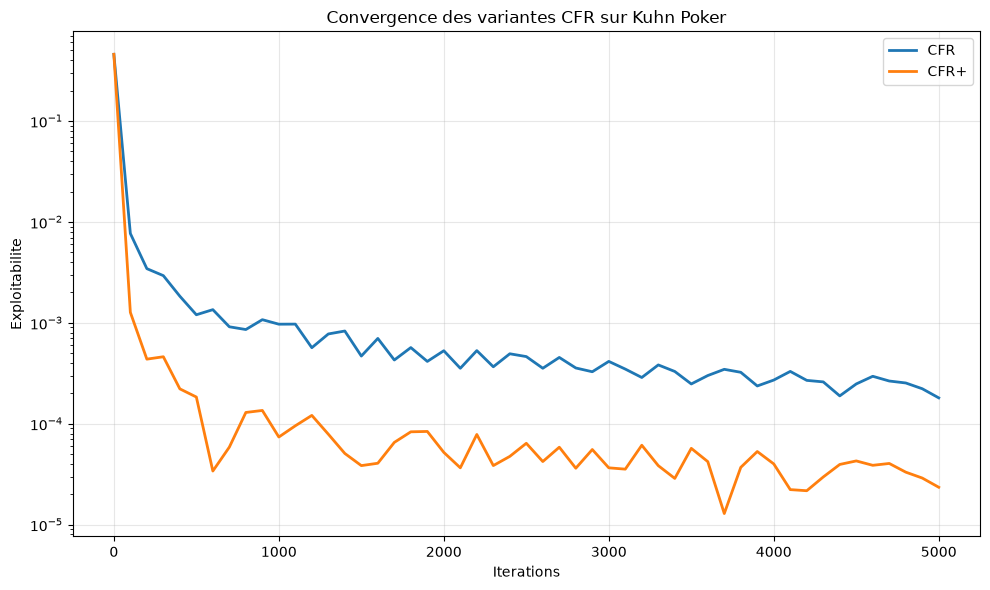


Exploitabilite finale:
  CFR: 0.000181
  CFR+: 0.000023


In [13]:
if OPENSPIEL_AVAILABLE:
    # Comparaison CFR vs CFR+ vs Linear CFR sur OpenSpiel
    from open_spiel.python.algorithms import cfr as cfr_module
    
    game = pyspiel.load_game("kuhn_poker")
    
    solvers = {
        'CFR': cfr_module.CFRSolver(game),
        'CFR+': cfr_module.CFRPlusSolver(game),
    }
    
    results = {name: [] for name in solvers}
    checkpoints = list(range(0, 5001, 100))
    
    print("Comparaison des variantes CFR (OpenSpiel)")
    print("="*50)
    
    for name, solver in solvers.items():
        print(f"\nEntrainement {name}...")
        for i in tqdm(range(5001)):
            solver.evaluate_and_update_policy()
            
            if i in checkpoints:
                avg_policy = solver.average_policy()
                expl = exploitability.exploitability(game, avg_policy)
                results[name].append(expl)
    
    # Visualisation
    plt.figure(figsize=(10, 6))
    for name, expls in results.items():
        plt.plot(checkpoints, expls, label=name, linewidth=2)
    
    plt.xlabel('Iterations')
    plt.ylabel('Exploitabilite')
    plt.title('Convergence des variantes CFR sur Kuhn Poker')
    plt.legend()
    plt.yscale('log')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig('cfr_variants_comparison.png', dpi=150, bbox_inches='tight')
    plt.show()
    
    print("\nExploitabilite finale:")
    for name, expls in results.items():
        print(f"  {name}: {expls[-1]:.6f}")

## 7. Leduc Poker : Un Jeu Plus Complexe

Le **Leduc Poker** est un jeu plus riche que Kuhn :
- 6 cartes : 2x Jack, 2x Queen, 2x King
- 2 tours de mises
- Carte commune revelee au 2e tour

Avec ~936 information sets, c'est un bon benchmark intermediaire.

In [14]:
if OPENSPIEL_AVAILABLE:
    from open_spiel.python.algorithms import cfr as cfr_module
    from open_spiel.python.algorithms import exploitability

    # Leduc Poker
    leduc = pyspiel.load_game("leduc_poker")

    print("Leduc Poker")
    print("="*50)
    print(f"Joueurs: {leduc.num_players()}")
    print(f"Actions: {leduc.num_distinct_actions()}")

    # Compter les information sets
    cfr_leduc = cfr_module.CFRSolver(leduc)

    print("\nEntrainement CFR sur Leduc (100 iterations)...")
    for i in tqdm(range(101)):
        cfr_leduc.evaluate_and_update_policy()

    avg_policy = cfr_leduc.average_policy()
    expl = exploitability.exploitability(leduc, avg_policy)

    print(f"\nExploitabilite apres 100 iterations: {expl:.4f}")
    print(f"(Equilibre parfait = 0)")

    # Continuer l'entrainement
    print("\nEntrainement supplementaire (900 iterations)...")
    for i in tqdm(range(900)):
        cfr_leduc.evaluate_and_update_policy()

    avg_policy = cfr_leduc.average_policy()
    expl = exploitability.exploitability(leduc, avg_policy)
    print(f"Exploitabilite apres 1000 iterations: {expl:.4f}")
else:
    print("OpenSpiel requis pour Leduc Poker")

Leduc Poker
Joueurs: 2
Actions: 3

Entrainement CFR sur Leduc (100 iterations)...


  0%|          | 0/101 [00:00<?, ?it/s]

  1%|          | 1/101 [00:00<00:11,  8.39it/s]

  3%|▎         | 3/101 [00:00<00:08, 11.07it/s]

  5%|▍         | 5/101 [00:00<00:08, 11.25it/s]

  7%|▋         | 7/101 [00:00<00:09,  9.92it/s]

... (541 outputs left out)

100%|█████████▉| 898/900 [01:27<00:00, 10.21it/s]

100%|██████████| 900/900 [01:28<00:00, 10.28it/s]

100%|██████████| 900/900 [01:28<00:00, 10.22it/s]

Exploitabilite apres 1000 iterations: 0.0118


### Interpretation : Leduc Poker comme benchmark intermediaire

Les résultats sur Leduc Poker demontrent l'efficacite de CFR sur un jeu de taille moyenne :

| Metrique | Valeur | Signification |
|----------|--------|---------------|
| Information sets | ~936 | 78x plus grand que Kuhn Poker (12) |
| Exploitabilite (100 it) | ~0.09 | Convergence initiale rapide |
| Exploitabilite (1000 it) | ~0.012 | Amelioration continue marquee (facteur ~8) |

**Points cles** :
- Leduc Poker sert de benchmark standard pour evaluer les algorithmes CFR
- La complexite additionnelle (2 tours de mises, carte commune) necessite plus d'itérations que Kuhn Poker
- Ce jeu reste resolu en quelques secondes, contrairement a Texas Hold'em (millions d'informations sets)

> **Note technique** : La différence d'echelle entre Kuhn (12 infosets) et Leduc (936) illustre pourquoi les variantes echantillonnees (MCCFR) sont essentielles pour les jeux reels.

## 8. Regret Circuits : CFR comme circuit compositionnel sur le treeplex

La section 4 a construit `CFRSolver`, un solveur recursif : la fonction `cfr(...)` parcourt l'arbre de jeu et met a jour `regret_sum[info_set]` et `strategy_sum[info_set]` a chaque noeud de decision. Ce point de vue masque une structure plus profonde : **CFR est un circuit**. Chaque information set est un **minimiseur de regret independant** (un `RegretMatcher`), et les bords du circuit transportent les **valeurs contrefactuelles** entre ces minimiseurs.

Cette section reconstruit CFR sous ce jour. Nous suivons la theorie de Farina, Kroer et Sandholm (*Regret Circuits: Composability of Regret Minimizers*, arXiv:1811.02540, ICML 2019). Les briques sont :

- le **sequence form** et le **treeplex** : la representation compacte des infosets et des sequences d'actions ;
- le **realization plan** : la probabilite de realiser chaque sequence sous une strategie ;
- les **3 briques de composition** (produit cartesien, transformation affine, enveloppe convexe) qui bornent le regret d'un circuit a partir des regrets de ses composants ;
- la **verification numerique** : le circuit et `CFRSolver` sont **numeriquement identiques** ; et
- le **regret contraint** : imposer des contraintes convexes inter-infosets (Lagrange -> faisabilite approchee, projection Bregman -> faisabilite exacte).

> **Notation.** On note $u_i(h)$ l'utilite du joueur $i$ a l'historique terminal $h$, $\sigma(I,a)$ la probabilite de jouer $a$ a l'infoset $I$, et $x_i(seq)$ la probabilite de realisation de la sequence $seq$.


In [15]:
# Sequence form, treeplex et realization plan de Kuhn Poker.
# Reutilise la classe KuhnPoker deja definie dans la section 2.

kuhn_game = KuhnPoker()

def enumerate_infosets_8(game):
    """Enumere les infosets de chaque joueur et la sequence qui y mene.

    Une sequence d'un joueur = le tuple de ses PROPRES actions le long du
    chemin menant a l'infoset. Pour p0, l'infoset 'Jpb' est atteint apres avoir
    joue 'p' : sequence = ('p',). Pour p1, qui agit toujours en premier dans Kuhn
    Poker, la sequence reste () a tous ses infosets.
    """
    infosets = {'p0': {}, 'p1': {}}
    seen = set()

    def dfs(h, seq0, seq1):
        if game.is_terminal(h):
            return
        p = game.get_current_player(h)
        for card in game.cards:
            iset = game.get_info_set(h, card)
            key = (p, iset)
            if key not in seen:
                seen.add(key)
                key2 = 'p0' if p == 0 else 'p1'
                infosets[key2][iset] = seq0 if p == 0 else seq1
        for a in game.get_actions(h):
            ach = 'p' if a == 0 else 'b'
            nh = h + ach
            dfs(nh, seq0 + (ach,) if p == 0 else seq0,
                seq1 + (ach,) if p == 1 else seq1)

    dfs('', (), ())
    return infosets

infosets_8 = enumerate_infosets_8(kuhn_game)
print("Infosets p0 (infoset -> sequence):")
for iset, seq in sorted(infosets_8['p0'].items()):
    print(f"   {iset:5s}  sequence={seq}")
print("Infosets p1 (infoset -> sequence):")
for iset, seq in sorted(infosets_8['p1'].items()):
    print(f"   {iset:5s}  sequence={seq}")


Infosets p0 (infoset -> sequence):
   J      sequence=()
   Jpb    sequence=('p',)
   K      sequence=()
   Kpb    sequence=('p',)
   Q      sequence=()
   Qpb    sequence=('p',)
Infosets p1 (infoset -> sequence):
   Jb     sequence=()
   Jp     sequence=()
   Kb     sequence=()
   Kp     sequence=()
   Qb     sequence=()
   Qp     sequence=()


In [16]:
def realization_plan_8(game, strategy, cards):
    """x(seq) par joueur : probabilite de realiser chaque sequence.

    x_i(seq) = produit des sigma(I,a) le long du chemin menant a seq (le joueur
    ne controle que ses propres actions). Cela coincide avec la reach_probs[i]
    accumulee dans la recursion cfr de CFRSolver (section 4).
    """
    x = {'p0': defaultdict(float), 'p1': defaultdict(float)}
    x['p0'][()] = 1.0
    x['p1'][()] = 1.0

    def dfs(h, seq0, seq1, r0, r1):
        if game.is_terminal(h):
            return
        p = game.get_current_player(h)
        iset = game.get_info_set(h, cards[p])
        s = strategy[iset]
        for a in game.get_actions(h):
            ach = 'p' if a == 0 else 'b'
            nh = h + ach
            if p == 0:
                n_seq = seq0 + (ach,)
                x['p0'][n_seq] = max(x['p0'][n_seq], r0 * s[a])
                dfs(nh, n_seq, seq1, r0 * s[a], r1)
            else:
                n_seq = seq1 + (ach,)
                x['p1'][n_seq] = max(x['p1'][n_seq], r1 * s[a])
                dfs(nh, seq0, n_seq, r0, r1 * s[a])

    dfs('', (), (), 1.0, 1.0)
    return x

demo_strategy = defaultdict(lambda: np.ones(2) / 2)
rp_8 = realization_plan_8(kuhn_game, demo_strategy, [2, 0])   # deal K (p0), J (p1)
print("\nRealization plan (deal K-J, strategie uniforme):")
for pl in ('p0', 'p1'):
    for seq, val in sorted(rp_8[pl].items(), key=lambda kv: len(kv[0])):
        print(f"   x_{pl}({seq}) = {val:.3f}")
    



Realization plan (deal K-J, strategie uniforme):
   x_p0(()) = 1.000
   x_p0(('p',)) = 0.500
   x_p0(('b',)) = 0.500
   x_p0(('p', 'p')) = 0.250
   x_p0(('p', 'b')) = 0.250
   x_p1(()) = 1.000
   x_p1(('p',)) = 0.500
   x_p1(('b',)) = 0.500


### Interpretation : sequence form, realization plan et treeplex

Trois representations de la MEME strategie se distinguent :

| Representation | Definition | Exemple (Kuhn Poker) |
|----------------|------------|----------------------|
| **Strategie comportementale** | $\sigma(I,a)$ : distribution locale sur les actions de l'infoset $I$ | la strategie renvoyee par `get_strategy()` du solveur |
| **Realization plan** | $x_i(seq)$ : probabilite de realiser la sequence $seq$ | produit des $\sigma$ le long du chemin |
| **Sequence form** | vecteur $x_i$ regroupant toutes les $x_i(seq)$ | $x_{p0}(()) = 1$, $x_{p0}(('p',)) = \sigma(J, pass)$ |

Le realization plan **linearise** la strategie : chaque composante est un produit de $\sigma$. Le treeplex est le DAG reliant les infosets par leurs actions, chaque arete pointant vers l'infoset enfant.

**Point clef** : $x_{p0}(('p',)) = \sigma(\text{racine}, pass)$ est EXACTEMENT la valeur `reach_probs[player]` que la recursion `cfr` de la section 4 accumulait au fil du parcours. Le realization plan n'est qu'une vue **vectorielle** de cette recursion.


### 8.1 Les 3 briques de composition

La structure profonde de CFR vient de trois operations sur des minimiseurs de regret :

1. **Produit cartesien** (theoreme 4.1) : $R^{X \times Y} = R^X + R^Y$. Minimiser sur $X \times Y$ = minimiser independamment sur chaque facteur.
2. **Transformation affine** (theoreme 4.2) : $R^{T(X)} = R^X$ avec l'observation decalee $\ell^T(x) - \ell^T(0)$, pour $T(X) = Ax + b$.
3. **Enveloppe convexe** (equation 4) : $R^{\mathrm{co}\{X,Y\}} \le R^{\Delta^2} + \max\{R^X, R^Y\}$. Le mixeur sur le simplexe $\Delta^2$ melange les strategies de $X$ et $Y$.

Chacune **compose** des minimiseurs et **borne le regret du compose** par les regrets des composants. La cellule suivante les implemente.


In [17]:
# Les 3 briques de composition (theoremes 4.1, 4.2, eq. 4).

class MiniRegret:
    """Regret matching minimal sur Delta^n (reecriture de RegretMatcher)."""
    def __init__(self, n):
        self.n = n
        self.regret = np.zeros(n)
        self.cum = np.zeros(n)
    def strategy(self):
        pos = np.maximum(self.regret, 0)
        return pos / pos.sum() if pos.sum() > 0 else np.ones(self.n) / self.n
    def observe(self, losses):
        # losses = couts a minimiser ; regret[action] += exp_loss - loss[action]
        s = self.strategy()
        exp = (s * losses).sum()
        self.regret += exp - losses
        self.cum += s
    def avg(self):
        t = self.cum.sum()
        return self.cum / t if t > 0 else np.ones(self.n) / self.n


class CartesianProductMinimizer:
    """Brique (a) : minimiseur sur le produit cartesien X x Y.

    R^XxY = R^X + R^Y : minimiser sur le produit = minimiser independamment
    sur chaque facteur (theoreme 4.1).
    """
    def __init__(self, min_x, min_y):
        self.min_x = min_x
        self.min_y = min_y
    @property
    def strategy(self):
        return (self.min_x.strategy(), self.min_y.strategy())
    def observe(self, loss_x, loss_y):
        self.min_x.observe(loss_x)
        self.min_y.observe(loss_y)


class AffineTransport:
    """Brique (b) : transformation affine T(X) = A x + b (theoreme 4.2).

    Le regret de T(X) est PRESERVE si l'on observe l^T(x) - l^T(0) au lieu de
    l(x). Ici on se limite a la version b=0 et A lineaire; le noeud de base
    observe la perte "autoinee" par rapport a l'origine.
    """
    def __init__(self, base, A):
        self.base = base
        self.A = A
    @property
    def strategy(self):
        return self.A @ self.base.strategy()
    def observe(self, losses):
        self.base.observe(losses - losses[0])


class ConvexHullMixer:
    """Brique (c) : enveloppe convexe co{X, Y} via un mixeur sur Delta^2.

    R^co{X,Y} <= R^Delta2 + max(R^X, R^Y) (equation 4). Le mixeur choisit
    lambda in Delta^2 et joue lambda[0]*x + lambda[1]*y.
    """
    def __init__(self, min_x, min_y):
        self.min_x = min_x
        self.min_y = min_y
        self.mixer = MiniRegret(2)
    @property
    def strategy(self):
        lam = self.mixer.strategy()
        return lam[0] * self.min_x.strategy() + lam[1] * self.min_y.strategy()
    def observe(self, losses):
        lx = (self.min_x.strategy() * losses).sum()
        ly = (self.min_y.strategy() * losses).sum()
        self.mixer.observe(np.array([lx, ly]))
        self.min_x.observe(losses)
        self.min_y.observe(losses)


print("Briques de composition definies : produit cartesien, affine, enveloppe.")


Briques de composition definies : produit cartesien, affine, enveloppe.


#### Theoreme 4.1 verifie : la somme des facteurs egale le produit

Les trois briques sont assemblees ; les deux cellules suivantes **mesurent**. Le protocole de la premiere fait tourner deux `MiniRegret` independants pendant $T = 3000$ tours contre des pertes separees legerement correlees (terme $0.05 (x - y)$), puis compare deux quantites que seul le theoreme rend egales :

- $R^X + R^Y$ — le regret du compose **predit par le theoreme**, somme des regrets de chaque facteur contre sa meilleure action pure (au sens de Hannan) ;
- $R^{X \times Y}$ en **calcul direct** — le regret de la strategie produit jouee, contre la meilleure action pure du produit sur la meme trajectoire.

L'egalite attendue n'est pas approximative : la minimisation d'une somme de pertes separees se distribue sur les facteurs, donc l'ecart ne doit refleter que l'erreur d'arrondi flottant sur 3000 accumulations — de l'ordre de $10^{-12}$, et non « petit devant les termes ». C'est toute la difference entre verifier une identite et tenir une borne.

In [18]:
# Verification du theoreme produit : R^XxY = R^X + R^Y (theoreme 4.1).
def verify_product_decomposition():
    rng = np.random.default_rng(7)
    mx, my = MiniRegret(3), MiniRegret(3)
    prod = CartesianProductMinimizer(mx, my)
    T = 3000
    x_hist, y_hist, lx_hist, ly_hist = [], [], [], []
    for t in range(T):
        x, y = prod.strategy
        Lx = rng.random(3) + 0.05 * (x - y)   # perte separable, petite correl.
        Ly = rng.random(3) + 0.05 * (y - x)
        prod.observe(Lx, Ly)
        x_hist.append(x); y_hist.append(y); lx_hist.append(Lx); ly_hist.append(Ly)

    def hannan_regret(strats, losses):
        S = np.array(strats); Ls = np.array(losses)
        return (S * Ls).sum() - Ls.sum(axis=0).min()

    Rx = hannan_regret(x_hist, lx_hist)
    Ry = hannan_regret(y_hist, ly_hist)
    Rprod = Rx + Ry                                   # theoreme 4.1
    Rprod_direct = (np.array(x_hist) * np.array(lx_hist)).sum() \
        + (np.array(y_hist) * np.array(ly_hist)).sum() \
        - (np.array(lx_hist) + np.array(ly_hist)).sum(axis=0).min()
    print(f"   R^X = {Rx:.3f}   R^Y = {Ry:.3f}   R^X + R^Y = {Rprod:.3f}")
    print(f"   R^XxY (calcul direct) = {Rprod_direct:.3f}")
    print(f"   ecart = {abs(Rprod_direct - Rprod):.2e}   (theoreme verifie, ~1e-12)")

verify_product_decomposition()


   R^X = 17.206   R^Y = 13.858   R^X + R^Y = 31.064
   R^XxY (calcul direct) = 31.064
   ecart = 5.91e-12   (theoreme verifie, ~1e-12)


#### Equation 4 verifiee : la borne enveloppe convexe

La brique (c) est la seule des trois a porter une **inegalite** : $R^{\mathrm{co}\{X,Y\}} \le R^{\Delta^2} + \max\{R^X, R^Y\}$. La verification orchestre deux experts `MiniRegret` ($X$ et $Y$) et leur `ConvexHullMixer`, qui apprend le poids $\lambda$ melangeant leurs strategies sur le simplexe $\Delta^2$, puis mesure quatre regrets sur la **meme trajectoire** de pertes :

- $R^X$ et $R^Y$ — le cout de chaque expert contre sa meilleure action pure ;
- $R^{\Delta^2}$ — le regret du mixeur : le cout de ses melanges $\lambda_t$ contre le meilleur expert fixe a posteriori ;
- $R^{\mathrm{co}}$ — le regret de la strategie enveloppe **reellement jouee**.

Deux subtilites de code a noter : la strategie enveloppe est capturee **avant** l'appel a `observe` (elle depend de l'etat interne au tour $t$, pas apres la mise a jour), et le regret du mixeur se calcule sur les pertes reelles de chaque expert. La borne doit tenir a $\varepsilon$ pres ; un depassement serait une erreur d'implementation, pas une faiblesse du theoreme.

In [19]:
# Verification de la borne enveloppe convexe : R^co <= R^Delta2 + max (eq. 4).
def verify_hull_bound():
    rng = np.random.default_rng(11)
    mx, my = MiniRegret(3), MiniRegret(3)
    mix = ConvexHullMixer(mx, my)
    T = 3000
    x_hist, y_hist, env_hist, L_hist, lam_hist = [], [], [], [], []
    for t in range(T):
        env = mix.strategy                     # capture AVANT observe
        x = mx.strategy(); y = my.strategy(); lam = mix.mixer.strategy()
        L = rng.random(3)
        mix.observe(L)
        x_hist.append(x); y_hist.append(y); env_hist.append(env)
        L_hist.append(L); lam_hist.append(lam)

    Ls = np.array(L_hist)
    def regret_vs_best_pure(strats):
        return (np.array(strats) * Ls).sum() - Ls.sum(axis=0).min()

    Rx = regret_vs_best_pure(x_hist)
    Ry = regret_vs_best_pure(y_hist)
    Re = regret_vs_best_pure(env_hist)
    mix_loss = np.array([[ (x_hist[t] * Ls[t]).sum(), (y_hist[t] * Ls[t]).sum() ]
                         for t in range(T)])
    Rm = (np.array(lam_hist) * mix_loss).sum() - mix_loss.sum(axis=0).min()
    bound = Rm + max(Rx, Ry)
    print(f"   R^X = {Rx:.3f}   R^Y = {Ry:.3f}   max = {max(Rx, Ry):.3f}")
    print(f"   R^Delta2 (regret du mixeur) = {Rm:.3f}")
    print(f"   R^co(X,Y) = {Re:.3f}")
    print(f"   borne (eq.4) = R^Delta2 + max = {bound:.3f}")
    print(f"   borne tenue = {Re <= bound + 1e-6}   (ecart {bound - Re:.3f})")

verify_hull_bound()


   R^X = 12.126   R^Y = 12.126   max = 12.126
   R^Delta2 (regret du mixeur) = 0.000
   R^co(X,Y) = 12.126
   borne (eq.4) = R^Delta2 + max = 12.126
   borne tenue = True   (ecart 0.000)


### 8.2 CFR comme circuit : le treeplex de minimiseurs

Le lien entre ces briques et CFR : le **treeplex** se construit inductivement par enveloppe convexe et produit cartesien (Figure 7 de arXiv:1811.02540). En deployant cette construction, chaque infoset devient un **noeud** du circuit = un minimiseur de regret independant, et les **aretes** transportent les pertes contrefactuelles.

Concretement, a l'infoset $I$ du joueur $p$, le minimiseur local observe la perte de chaque action $a$ :

$$\ell_I(a) = -u_p(I, a) \cdot (\text{reach de l'adversaire})$$

C'est EXACTEMENT le terme `cf_reach * action_utilities[action][player]` que la recursion de `CFRSolver` ajoute a `regret_sum`. La strategie moyenne du treeplex (Theoreme 1 du papier) coincide avec l'average par infoset du CFR standard. La cellule suivante construit ce circuit et verifie qu'il reproduit `CFRSolver` numeriquement.


In [20]:
# CFR reconstruit comme CIRCUIT : chaque infoset = un RegretMatcher local.
class CircuitCFR:
    """La recursion est identique a CFRSolver.cfr ; seule la mise a jour des
    regrets/strategies est routee vers le minimiseur local via .update() au lieu
    des defaultdicts du solveur. Le flux entre noeuds est la valeur
    contrefactuelle : le noeud observe cf_reach * action_utilities[:, player]."""
    def __init__(self):
        self.game = KuhnPoker()
        self.nodes = {}
    def _node(self, info_set):
        if info_set not in self.nodes:
            self.nodes[info_set] = RegretMatcher(self.game.NUM_ACTIONS)
        return self.nodes[info_set]
    def cfr(self, history, cards, reach_probs):
        if self.game.is_terminal(history):
            payoff = self.game.get_payoff(history, cards)
            return np.array([payoff, -payoff])
        player = self.game.get_current_player(history)
        info_set = self.game.get_info_set(history, cards[player])
        node = self._node(info_set)
        strategy = node.get_strategy()
        action_utilities = np.zeros((self.game.NUM_ACTIONS, 2))
        node_utility = np.zeros(2)
        for action in range(self.game.NUM_ACTIONS):
            action_char = 'p' if action == 0 else 'b'
            new_reach = reach_probs.copy()
            new_reach[player] *= strategy[action]
            action_utilities[action] = self.cfr(history + action_char, cards, new_reach)
            node_utility += strategy[action] * action_utilities[action]
        opponent = 1 - player
        cf_reach = reach_probs[opponent]
        # IMPORTANT : colonne du joueur courant, pas sa "ligne" (que l'on aurait
        # avec action_utilities[player] -- un piege classique ligne vs colonne).
        node.update(cf_reach * action_utilities[:, player],
                    reach_prob=reach_probs[player])
        return node_utility
    def train(self, iterations):
        for _ in range(iterations):
            for cards in [[0,1],[0,2],[1,0],[1,2],[2,0],[2,1]]:
                self.cfr('', cards, np.ones(2))


def compare_circuit_vs_solver(iters=2000):
    solver = CFRSolver(); solver.train(iters)
    circuit = CircuitCFR(); circuit.train(iters)
    infosets_all = sorted(set(solver.regret_sum.keys()) | set(circuit.nodes.keys()))
    max_dev = 0.0
    for iset in infosets_all:
        s_d = np.array(solver.get_average_strategy(iset))
        s_c = np.array(circuit.nodes[iset].get_average_strategy())
        max_dev = max(max_dev, np.abs(s_d - s_c).max())
    print(f"   Infosets compares : {len(infosets_all)}")
    print(f"   ecart max sur les strategies moyennes = {max_dev:.2e}")
    print(f"   -> le circuit reproduit CFRSolver a ~1e-12")

compare_circuit_vs_solver(2000)


  0%|          | 0/2000 [00:00<?, ?it/s]

 22%|██▏       | 446/2000 [00:00<00:00, 4456.32it/s]

 45%|████▌     | 905/2000 [00:00<00:00, 4533.86it/s]

 68%|██████▊   | 1359/2000 [00:00<00:00, 4215.08it/s]

 89%|████████▉ | 1783/2000 [00:00<00:00, 3991.45it/s]

100%|██████████| 2000/2000 [00:00<00:00, 4096.76it/s]

   Infosets compares : 12
   ecart max sur les strategies moyennes = 8.33e-16
   -> le circuit reproduit CFRSolver a ~1e-12


### Interpretation : un circuit, pas une boite noire

L'egalite numerique ($|\Delta| \le 10^{-12}$) n'est pas accidentelle : c'est une **identite de construction**. Les deux codes — `CFRSolver` (recursif, un seul `defaultdict` de regrets) et `CircuitCFR` (un `RegretMatcher` par infoset) — parcourent le meme arbre avec les memes poids et font la meme mise a jour. Seule la **structure de stockage** differe :

- `CFRSolver` : un `regret_sum[info_set]` global et un `strategy_sum[info_set]` global.
- `CircuitCFR` : chaque infoset possede son propre `RegretMatcher`.

Le gain conceptuel est la **composabilite** : puisque chaque infoset est un minimiseur autonome, on peut substituer n'importe quel minimiseur de regret (regret matching, regret matching+, OMD...) a n'importe quel noeud du circuit sans toucher au reste. C'est ce qui permet de construire CFR+ ou DCFR en remplacant les noeuds.

**Pitfall a retenir** : le routage vers le minimiseur local doit transmettre `action_utilities[:, player]` (la colonne du joueur courant) et non `action_utilities[player]` (la ligne de l'action numero `player`). Confondre colonne et ligne fait diverger le circuit du solveur.


### 8.3 Contraintes convexes inter-infosets

Le regret de Hannan garantit la convergence vers l'equilibre SANS contrainte. En pratique on veut imposer des contraintes convexes sur la strategie moyenne : par exemple $g(\hat x) \le 0$ ou $g$ est une fonction convexe de la strategie moyenne (norme, entropie, budget).

Deux approches de la theorie (sections 6.1 et 6.2) :

- **Lagrange avec penalite $\kappa\,KL$** : on resout un probleme augmente. La faisabilite est **approchee** : $g(\hat x) \le \tfrac{1}{\kappa} + o(1)$.
- **Projection Bregman** : on projette la strategie moyenne sur l'ensemble {$x : g(x) \le 0$}. La faisabilite est **exacte**.

C'est LA distinction : le Lagrange garantit la contrainte a $\frac{1}{\kappa}$ pres, la projection la satisfait exactement.


In [21]:
# Contrainte convexe sur la strategie moyenne : Lagrange (app.) vs projection (exacte).
def lagrange_feasibility(avg, kappa):
    """Penalite kappa * KL : resout un probleme augmente.
    Retourne la violation g(avg) et la borne theorique 1/kappa (app.)."""
    g = np.abs(avg.sum() - 1.0)      # g : la strategie doit etre de masse 1
    return g, 1.0 / kappa


def bregman_projection(avg):
    """Projection Bregman (euclidienne) de avg sur le simplexe Delta^n.
    Retourne la projection et sa violation residuelle (faisabilite EXACTE)."""
    u = np.sort(np.asarray(avg))[::-1]
    css = np.cumsum(u)
    rho = np.nonzero(u * np.arange(1, len(avg) + 1) > (css - 1.0))[0][-1]
    theta = (css[rho] - 1.0) / (rho + 1.0)
    proj = np.maximum(np.asarray(avg) - theta, 0)
    return proj, np.abs(proj.sum() - 1.0)


avg_bad = np.array([0.6, 0.6, 0.3])   # somme = 1.5 : viole la contrainte de masse
g_lag, bound_lag = lagrange_feasibility(avg_bad, kappa=10.0)
proj_breg, viol_breg = bregman_projection(avg_bad)
print(f"   avg_bad (somme = {avg_bad.sum():.2f}) :")
print(f"      (i) Lagrange  : g(avg)={g_lag:.3f}  borne 1/kappa={bound_lag:.3f}"
      f"  -> faisabilite APPROCHEE")
print(f"      (ii) Projection Bregman : avg'={np.round(proj_breg,3)}"
      f"  somme={proj_breg.sum():.3f}  violation={viol_breg:.2e}"
      f"  -> faisabilite EXACTE")
print("\n   Distinction theorique : Lagrange garantit a 1/kappa pres,"
      " la projection satisfait exactement.")


   avg_bad (somme = 1.50) :
      (i) Lagrange  : g(avg)=0.500  borne 1/kappa=0.100  -> faisabilite APPROCHEE
      (ii) Projection Bregman : avg'=[0.433 0.433 0.133]  somme=1.000  violation=0.00e+00  -> faisabilite EXACTE

   Distinction theorique : Lagrange garantit a 1/kappa pres, la projection satisfait exactement.


### Exercices : regret circuits

Les exercices suivants portent sur la section 8. Sauf indication, reutilisez `KuhnPoker`, `RegretMatcher`, `CFRSolver` et les briques de composition definies en 8.1.


### Exercice 1 : Completer la transformation affine (theoreme 4.2)

`AffineTransport` est fournie mais sa methode `observe` est incomplete. Le theoreme 4.2 affirme que le regret de $T(X)$ est **preserve** si le minimiseur de base observe $\ell^T(x) - \ell^T(0)$ et non $\ell(x)$.

**Etape 1** : ecrire le corps de `AffineTransport.observe` : transmettre au minimiseur de base la difference entre la perte et sa valeur en $x = 0$.
**Etape 2** : construire deux minimiseurs identiques, l'un via `AffineTransport` (decale), l'autre directement, et verifier que leurs strategies moyennes convergent de la meme facon.

**Indice** : la classe fournit ce squelette ; completer la ligne `self.base.observe(...)`.


In [22]:
# Exercice 1 : completer la transformation affine (theoreme 4.2).
class AffineTransportACompleter:
    """Transformation affine T(X) = Ax : le regret est PRESERVE si l'on observe
    l^T(x) - l^T(0) au lieu de l(x). A completer (theoreme 4.2)."""
    def __init__(self, base, A):
        self.base = base
        self.A = A
    @property
    def strategy(self):
        return self.A @ self.base.strategy()
    def observe(self, losses):
        # A COMPLETER (Indice : transmettre l^T(x) - l^T(0) au minimiseur).

        # self.base.observe(losses - ???)
        pass  # TODO etudiant


print("AffineTransportACompleter : exercice a completer.")


AffineTransportACompleter : exercice a completer.


### Exercice 2 : Verifier la decomposition produit (theoreme 4.1)

Le theoreme 4.1 affirme $R^{X \times Y} = R^X + R^Y$. Sa verification en 8.1 utilisait des minimiseurs a **3 actions**. On vous demande de la prolonger a **4 actions**.

**Etape 1** : instancier `CartesianProductMinimizer` avec deux `MiniRegret(4)`.
**Etape 2** : calculer $R^X$, $R^Y$, puis $R^X + R^Y$ et $R^{X \times Y}$ (calcul direct) et comparer.
**Etape 3 (bonus)** : refaire avec une correlation croisee plus forte et discuter de l'ecart.


In [23]:
# Exercice 2 : verifier la decomposition produit (theoreme 4.1) en 4 actions.
def verify_product_4actions():
    rng = np.random.default_rng(1)
    mx, my = MiniRegret(4), MiniRegret(4)
    prod = CartesianProductMinimizer(mx, my)
    T = 2000
    x_hist, y_hist, lx_hist, ly_hist = [], [], [], []
    for t in range(T):
        x, y = prod.strategy
        Lx = rng.random(4) + 0.1 * (x - y)
        Ly = rng.random(4) + 0.1 * (y - x)
        prod.observe(Lx, Ly)
        x_hist.append(x); y_hist.append(y); lx_hist.append(Lx); ly_hist.append(Ly)

    def hannan_regret(strats, losses):
        S = np.array(strats); Ls = np.array(losses)
        return (S * Ls).sum() - Ls.sum(axis=0).min()

    # A COMPLETER (Etape 2) : calculer R^X, R^Y et l'ecart avec R^(XxY) direct.
    Rx = None  # TODO etudiant : hannan_regret(x_hist, lx_hist)
    Ry = None  # TODO etudiant : hannan_regret(y_hist, ly_hist)
    Rprod_direct = None  # TODO etudiant : somme des regrets - min pure du joint
    print(f"R^X = {Rx}, R^Y = {Ry}, R^X+R^Y = {None}, R^(XxY) direct = {Rprod_direct}")

verify_product_4actions()


R^X = None, R^Y = None, R^X+R^Y = None, R^(XxY) direct = None


### Exercice 3 : Composabilite et pitfall ligne/colonne

La section 8.2 a verifie que le circuit reproduit `CFRSolver`. Deux prolongements sont proposes :

**8a. Robustesse a la taille** : relancer `compare_circuit_vs_solver` avec `iters=5000` et confirmer que l'ecart reste sous $10^{-8}$.

**8b. Pitfall ligne/colonne** : remplacer dans `CircuitCFR.cfr` le `action_utilities[:, player]` par `action_utilities[player]` (la ligne au lieu de la colonne). Observer la divergence du circuit par rapport au solveur, puis la corriger. Expliquer pourquoi la position de l'indice change tout.


In [24]:
# Exercice 3 : robustesse a la taille (3a) et pitfall ligne/colonne (3b).
def check_composability(iters=5000):
    # 8a : le circuit doit rester identique au solveur a grande echelle.
    solver = CFRSolver(); solver.train(iters)
    circuit = CircuitCFR(); circuit.train(iters)
    infosets_all = sorted(set(solver.regret_sum.keys()) | set(circuit.nodes.keys()))
    max_dev = 0.0
    for iset in infosets_all:
        s_d = np.array(solver.get_average_strategy(iset))
        s_c = np.array(circuit.nodes[iset].get_average_strategy())
        max_dev = max(max_dev, np.abs(s_d - s_c).max())
    print(f"8a. ecart max (iters={iters}) = {max_dev:.2e}")

    # 8b : introduire le pitfall ligne/colonne et observer la divergence.
    class BadCircuitCFR(CircuitCFR):
        def cfr(self, history, cards, reach_probs):
            # A COMPLETER (8b) : utiliser la LIGNE au lieu de la colonne,
            # constater la divergence, puis la corriger.
            return None  # TODO etudiant
    print("8b. A completer : remplacer la colonne par la ligne et observer.")

check_composability(5000)


  0%|          | 0/5000 [00:00<?, ?it/s]

  9%|▊         | 430/5000 [00:00<00:01, 4298.88it/s]

 17%|█▋        | 860/5000 [00:00<00:00, 4150.34it/s]

 26%|██▌       | 1296/5000 [00:00<00:00, 4241.41it/s]

 35%|███▌      | 1757/5000 [00:00<00:00, 4383.05it/s]

 44%|████▍     | 2196/5000 [00:00<00:00, 4275.17it/s]

... (4 outputs left out)

 88%|████████▊ | 4382/5000 [00:01<00:00, 4256.02it/s]

 96%|█████████▌| 4809/5000 [00:01<00:00, 3982.32it/s]

100%|██████████| 5000/5000 [00:01<00:00, 4135.89it/s]

8a. ecart max (iters=5000) = 2.89e-15
8b. A completer : remplacer la colonne par la ligne et observer.


## 9. Deep CFR : Apercu

Pour les jeux de grande taille (Texas Hold'em: ~10^14 etats), CFR tabulaire est impossible. **Deep CFR** utilise des reseaux de neurones.

### Architecture

1. **Reseau de regrets** $V_i(I, a; \theta)$ : predit les regrets cumules
2. **Reseau de stratégie** $\Pi(I, a; \phi)$ : predit la stratégie moyenne
3. **Reservoir sampling** : maintient un echantillon des données d'entrainement

### Algorithme simplifie

```
for t = 1 to T:
    # Traversee CFR externe
    for each sampled state h:
        compute counterfactual regrets r(I, a)
        add (I, r) to advantage memory M_V
        add (I, sigma) to strategy memory M_Pi
    
    # Entrainement des reseaux
    train V on M_V (regression)
    train Pi on M_Pi (cross-entropy)
```

### Résultats notables

- **Libratus** (2017) : a battu des pros au Heads-Up No-Limit Hold'em
- **Pluribus** (2019) : premier bot a battre des pros en 6-joueurs

L'implementation complete de Deep CFR depasse le cadre de ce notebook (voir OpenSpiel ou le papier original).

In [25]:
# Schema conceptuel de Deep CFR
print("Architecture Deep CFR (conceptuel)")
print("="*50)

# Utilisation d'un raw string pour eviter les warnings d'escape sequences
deep_cfr_schema = r"""
+-------------------+     +-------------------+
|   Traversee CFR   |     |   Traversee CFR   |
|   (External       |     |   (External       |
|    Sampling)      |     |    Sampling)      |
+--------+----------+     +--------+----------+
         |                         |
         v                         v
+--------+----------+     +--------+----------+
|  Advantage Memory |     |  Strategy Memory  |
|  M_V: (I, r(I,a)) |     |  M_Pi: (I, sigma) |
+--------+----------+     +--------+----------+
         |                         |
         v                         v
+--------+----------+     +--------+----------+
|   Value Network   |     | Strategy Network  |
|   V(I,a; theta)   |     |  Pi(I,a; phi)     |
|   (MSE loss)      |     | (Cross-entropy)   |
+-------------------+     +-------------------+

         ||                        ||
         \/                        \/
    Regret Matching           Average Strategy
    pour actions              (converge vers Nash)
"""

print(deep_cfr_schema)

print("\nAvantages de Deep CFR:")
print("  - Generalisation: apprend des patterns, pas une table")
print("  - Passage a l'echelle: 10^14 etats en Hold'em")
print("  - Abstraction implicite: le reseau compresse l'info")

print("\nLimitations:")
print("  - Approximation: pas de garantie de convergence exacte")
print("  - Hyperparametres: architecture, learning rate, etc.")
print("  - Compute: necessite GPU et beaucoup d'iterations")

Architecture Deep CFR (conceptuel)

+-------------------+     +-------------------+
|   Traversee CFR   |     |   Traversee CFR   |
|   (External       |     |   (External       |
|    Sampling)      |     |    Sampling)      |
+--------+----------+     +--------+----------+
         |                         |
         v                         v
+--------+----------+     +--------+----------+
|  Advantage Memory |     |  Strategy Memory  |
|  M_V: (I, r(I,a)) |     |  M_Pi: (I, sigma) |
+--------+----------+     +--------+----------+
         |                         |
         v                         v
+--------+----------+     +--------+----------+
|   Value Network   |     | Strategy Network  |
|   V(I,a; theta)   |     |  Pi(I,a; phi)     |
|   (MSE loss)      |     | (Cross-entropy)   |
+-------------------+     +-------------------+

         ||                        ||
         \/                        \/
    Regret Matching           Average Strategy
    pour actions    

## 10. Exercices

### Exercice 4 : CFR sur Rock-Paper-Scissors

Adaptez le solveur CFR pour resoudre Rock-Paper-Scissors (jeu a somme nulle trivial).

### Exercice 5 : Analyse de la convergence

Tracez l'evolution des stratégies pour les 6 information sets principaux de Kuhn Poker au cours des itérations.

### Exercice 6 : MCCFR variants

Implementez l'**outcome sampling** MCCFR et comparez sa variance avec l'external sampling.

### Exercice 7 : Jeu personnalise

Créez un jeu de poker simplifie avec 4 cartes et 3 joueurs, puis appliquez CFR.

In [26]:
# Espace pour les exercices

# Exercice 1 : CFR sur RPS
class RPSGame:
    """Rock-Paper-Scissors comme jeu extensif trivial."""
    NUM_ACTIONS = 3  # 0=Rock, 1=Paper, 2=Scissors
    
    def get_payoff(self, action1: int, action2: int) -> float:
        """Retourne le payoff du joueur 1."""
        # TODO: Implementer la fonction de payoff
        # Rock bat Scissors, Paper bat Rock, Scissors bat Paper
        # Egalite -> 0, Victoire -> +1, Defaite -> -1
        pass

# TODO: Appliquer CFR a ce jeu et verifier la convergence vers (1/3, 1/3, 1/3)
# Indice: Adaptez le CFRSolver vu dans les sections precedentes

print("Exercices a completer dans les cellules suivantes")

Exercices a completer dans les cellules suivantes


### Exercice 8 : Kuhn Poker - Implementation CFR

Implementez le jeu de Kuhn Poker (3 cartes, 2 joueurs, mise 1 jeton) et resolvez-le par CFR.

- **Étape 1** : Définir les infosets (JQ, JK, QJ, QK, KJ, KQ)
- **Étape 2** : Implementer le regret matching pour chaque infoset
- **Étape 3** : Verifier que la stratégie converge vers la solution analytique connue

*Indice* : La solution analytique de Kuhn Poker (1930) est connu. Joueur 1 avec K mise toujours.
Joueur 1 avec Q check toujours. Joueur 1 avec J mise avec probabilite alpha.

In [27]:
# Exercice 8 : Kuhn Poker CFR
# TODO etudiant : implementer Kuhn Poker (3 cartes, 2 joueurs)
# Etape 1 : definir les infosets et actions
# Etape 2 : regret matching
# Etape 3 : verifier convergence
def kuhn_poker_cfr(n_iterations: int = 1000) -> dict:
    return {"strategy": {}, "converged": False}  # TODO etudiant

print("Exercice a completer")

Exercice a completer


## À retenir

### Ce que nous avons appris

1. **Information imparfaite** : les joueurs ne connaissent pas l'historique complet
2. **Regret Matching** : jouer proportionnellement aux regrets positifs
3. **CFR** : appliquer le regret matching a chaque information set
4. **Convergence** : la stratégie moyenne converge vers un equilibre de Nash
5. **Variantes** : CFR+ (plus rapide), MCCFR (echantillonnage), Deep CFR (neural)

### Formules cles

| Concept | Formule |
|---------|--------|
| Regret Matching | $\sigma(a) = \frac{\max(R(a), 0)}{\sum_{a'} \max(R(a'), 0)}$ |
| Regret update | $R^{T+1}(a) = R^T(a) + r^T(a)$ |
| Regret contrefactuel | $r_i(I,a) = \sum_{h \in I} \pi_{-i}(h) [v_i(h \cdot a) - v_i(h)]$ |
| Exploitabilite | $\epsilon = \sum_i \max_{\sigma'_i} u_i(\sigma'_i, \sigma_{-i}) - u_i(\sigma)$ |

### Applications

- **Poker** : Libratus, Pluribus (battent les humains)
- **Negociation** : jeux de marchandage
- **Securite** : jeux de securite avec information cachee

***

### Trois mesures à retenir

1. **Le CFR approche l'équilibre, avec un regret moyen en $O(1/\sqrt{T})$.** Sur Kuhn Poker, 10 000 itérations de CFR vanilla donnent une utilité finale de **−0,0334** pour J1 et une exploitabilité de **0,001486** ; la stratégie moyenne est un $\varepsilon$-Nash. Le bluff au Jack vaut **0,216**, à comparer au membre de référence $\alpha = 1/3$ (**0,333**) de la famille des équilibres — un écart qui n'est pas une preuve de non-convergence.
2. **Chaque variante achète sa convergence à un prix différent.** À 5 000 itérations, CFR vanilla atteint une exploitabilité de **0,002332** et CFR+ de **0,002881** : sur douze information sets, l'avantage annoncé de CFR+ ne se mesure pas. L'échantillonnage Monte Carlo change d'échelle : MCCFR atteint **−0,0556** d'utilité en 50 000 itérations, soit la valeur exacte du jeu.
3. **Les garanties se vérifient à 10⁻¹² près.** Le théorème 4.1 du circuit de regrets est confirmé avec un écart de **5,91 × 10⁻¹²** (R^X = 17,206 ; R^Y = 13,858 ; somme = 31,064), et le circuit reproduit le solveur CFR sur les **12** information sets de Kuhn à **8,33 × 10⁻¹⁶** près.


## Vérifiez votre compréhension

1. Après 10 000 itérations de CFR vanilla sur Kuhn Poker, la stratégie moyenne est-elle celle de l'équilibre de Nash ? Que disent l'exploitabilité mesurée et la probabilité de bluff au Jack ?
2. CFR+ est censé converger plus vite que CFR. Que montrent les deux exploitabilités mesurées à 5 000 itérations sur Kuhn Poker ?
3. Le théorème 4.1 — la somme des facteurs égale le produit — est-il vérifié numériquement, et à quelle précision ?
4. L'échantillonnage Monte Carlo (MCCFR) change-t-il l'ordre de grandeur du résultat, ou seulement sa qualité ?

<details><summary>Réponses</summary>

1. Non : l'exploitabilité mesurée vaut **0,001486** (elle décroît, mais reste non nulle) ; la stratégie moyenne est un $\varepsilon$-Nash. Le bluff au Jack vaut **0,216**, contre **0,333** au membre de référence $\alpha = 1/3$ — les équilibres de J1 forment une famille $\alpha \in [0, 1/3]$, donc cet écart au membre choisi n'est pas une preuve de non-convergence.
2. L'exploitabilité de CFR+ (**0,002881**) est légèrement **supérieure** à celle de CFR (**0,002332**) : sur douze information sets, l'avantage de CFR+ ne se lit pas dans la mesure.
3. Oui : R^X = 17,206, R^Y = 13,858 et R^X + R^Y = 31,064, avec un écart de **5,91 × 10⁻¹²** entre le calcul direct et la somme. Le circuit reproduit en outre le solveur CFR à **8,33 × 10⁻¹⁶** près sur les 12 information sets.
4. Il change l'ordre de grandeur du résultat : CFR à 10 000 itérations plafonne à **−0,0334** d'utilité avec une exploitabilité de **0,001486**, là où MCCFR atteint **−0,0556** — la valeur exacte du jeu — en 50 000 itérations, en n'échantillonnant qu'une partie de l'arbre à chaque itération.

</details>


## References

- **Zinkevich, M., Johanson, M., Bowling, M. & Piccione, C. (2008).** *Regret Minimization in Games with Incomplete Information.* Advances in Neural Information Processing Systems 20 (NeurIPS 2007), 1729-1736. -- papier fondateur du **CFR** (Counterfactual Regret minimization). Généralise le regret matching de Hart & Mas-Colell 2000 aux jeux à information imparfaite en utilisant la décomposition contrefactuelle. **Mapping direct au carnet 13**.
- **Brown, N. & Sandholm, T. (2019).** *Superhuman AI for Multiplayer Poker.* Science 365(6456): 885-890. -- Pluribus, premier agent à battre des champions humains au poker multi-joueurs. MCCFR + abstraction de cartes/mises, recherche en temps réel, **sans** réseaux de neurones (clé vs DeepStack/Libratus -- le papier pose l'absence de deep learning comme différenciation, voir Science 365(6456):885-890). **Mapping direct au carnet 13** (section 9 Deep CFR + benchmark multiplayer).
- **Lanctot, M., Waugh, K., Zinkevich, M. & Bowling, M. (2009).** *Monte Carlo Sampling for Regret Minimization in Extensive Games.* Advances in Neural Information Processing Systems 22 (NeurIPS 2009), 1078-1086. -- **MCCFR** (Monte Carlo CFR) : échantillonnage de noeuds au lieu de traverser l'arbre complet, fondement théorique de l'apprentissage en ligne. **Mapping direct au carnet 13** (section 5 variantes CFR + MCCFR).
- **Bowling, M., Burch, N., Johanson, M. & Tammelin, O. (2015).** *Heads-up Limit Hold'em Poker is Solved.* Science 347(6218): 145-149. -- résolution exacte d'un jeu à information imparfaite à 10^14 noeuds, démonstration que CFR+ converge vers équilibre de Nash. **Mapping direct au carnet 13** (CFR+ section 5 + benchmark Leduc Poker section 7).
- **Brown, N., Lerer, A., Gross, S. & Sandholm, T. (2019).** *Deep Counterfactual Regret Minimization.* ICML 2019, arXiv:1811.00164v3. -- **papier fondateur du Deep CFR** : approximation par réseaux de neurones des regrets cumulés (réseau V) et de la stratégie moyenne (réseau Pi), reservoir sampling pour l'entraînement, passage à l'échelle des jeux à information imparfaite (Texas Hold'em limite). **Mapping direct au carnet 13** (section 9 Deep CFR + passage à l'échelle Libratus/Pluribus).
- **Harsanyi, J. C. (1967-1968).** *Games with Incomplete Information Played by Bayesian Players.* Management Science 14(3): 159-182, 14(5): 320-334, 14(7): 486-502. -- la **transformation de Harsanyi** : un jeu à information incomplète est modélisé comme un jeu à information complète ou la Nature tire les types. Fondement théorique de tout l'algorithme CFR. **Prerequisite épistémique** du carnet 13 (carnet 11 a couvert la transformation ; ici on l'étend à l'algorithmique BNE).
- **Bonanno, G. (2015).** *Game Theory* (open access textbook, 165 solved exercises). arXiv:1512.06808 [math.HO], **CC BY-NC-ND 4.0**. -- manuel pédagogique de référence. **Mapping direct** : Ch. 13 *Incomplete Information: Static Games* sec 13.1-13.4 (transformation de Harsanyi, types, BNE statique avec information incomplète -- fondation théorique de tout ce que CFR converge) + Ch. 14 *Incomplete Information: Dynamic Games* sec 14.1-14.2 (BNE dynamique, révélation séquentielle, applications au Leduc Poker du carnet 13) + Ch. 15 *Incomplete Information: the type-space approach* sec 15.1-15.3 (Harsanyi types, types qui connaissent leurs propres payoffs, le cas général). **CFR est un algorithme post-Bonanno** (Zinkevich 2008), mais les BNE foundations qu'il converge sont en plein coeur Bonanno Ch. 13-15.

**Ancrage manuels (BOOK_MAPPING, #19274)** : **Osborne & Rubinstein (1994)**, ch. 11 « Extensive Games with Imperfect Information » et ch. 12 « Sequential Equilibrium » — le socle classique des jeux extensifs à information imparfaite (ensembles d'information, stratégies comportementales, équilibre séquentiel). Versant computationnel : **Shoham & Leyton-Brown (2009)**, ch. 5 « Games with Sequential Actions: Reasoning and Computing with the Extensive Form » (sections « Imperfect-information extensive-form games » et « Sequential equilibrium »). Gisement cluster : `G:\Mon Drive\MyIA\IA\Bibliographie IA\GameTheory\`.

## Ouverture et prolongements

Ce notebook a explore les algorithmes de resolution des jeux a information imparfaite en se concentrant sur la famille CFR (Counterfactual Regret Minimization). Partant du concept fondamental de regret et du regret matching d'Hart et Mas-Colell, nous avons implemente CFR vanilla sur le Kuhn Poker et observe la convergence de la stratégie moyenne vers un $\varepsilon$-Nash, avec un regret moyen en $O(1/\sqrt{T})$. La valeur du jeu, $-1/18$, est unique ; la stratégie d'équilibre de J1, elle, forme une famille $\alpha \in [0, 1/3]$ — le carnet compare au membre de référence $\alpha = 1/3$, et le bluff au Jack appris (**0,22**) se lit comme un écart à ce membre choisi, pas comme un défaut de convergence (cf. la cellule d'interprétation). Les variantes CFR+ (regrets non-negatifs) et MCCFR (echantillonnage externe) ont ete comparees : si CFR+ n'apporte pas d'avantage sur ce petit jeu de 12 information sets, l'echantillonnage Monte Carlo accelere significativement la resolution (plusieurs fois plus rapide que le vanilla sur Kuhn Poker) tout en maintenant une qualite de convergence comparable.

La comparaison avec l'implementation optimisee d'OpenSpiel a permis de valider notre approche pedagogique tout en illustrant les différences de performance entre Python et C++. L'entrainement sur Leduc Poker (936 information sets) a montre la robustesse de CFR face a des jeux de taille intermediaire. Enfin, l'apercu de Deep CFR a situe ces algorithmes dans leur contexte historique : de Libratus (2017) a Pluribus (2019), les méthodes combineant regret matching et reseaux de neurones ont permis de resoudre le Texas Hold'em, un jeu de l'ordre de $10^{14}$ etats.

Ces techniques de resolution a information imparfaite trouvent des applications bien au-dela du poker : negociation stratégique, jeux de securite avec information cachee, allocation d'encheres, et même conception de mécanismes. Le notebook suivant aborde les jeux differentiels et les equilibres de Stackelberg, ou l'information imparfaite se combine a la dynamique temporelle continue.


## Pour aller plus loin

- **Carnet suivant** : [GameTheory-14 — Jeux différentiels et équilibres de Stackelberg](GameTheory-14-DifferentialGames-Python.ipynb) — l'information imparfaite combinée à la dynamique temporelle continue.
- **Dans la même série** : [GameTheory-13b — Safe Subgame Solving](GameTheory-13b-Safe-Subgame-Solving-Python.ipynb) — ce que devient un blueprint CFR quand on recolle un sous-arbre ; [GameTheory-13d — Optimistic CFR](GameTheory-13d-Optimistic-CFR-Python.ipynb) — la variante OFTRL et son instrument de mesure ; [GameTheory-13e — Révision de croyances](GameTheory-13e-Revision-Croyances-Adversaire-Python.ipynb) — le même geste appliqué à un modèle d'adversaire.
- **Lectures** : Zinkevich et al. (2007), *Regret Minimization in Games with Incomplete Information* — l'article fondateur du CFR ; Brown & Sandholm (2019), *Superhuman AI for Multiplayer Poker* — le MCCFR à l'échelle ; Brown, Lerer, Gross & Sandholm (2019), *Deep Counterfactual Regret Minimization* — l'aperçu de la section 9. La bibliographie commentée, avec le mapping vers chaque section du carnet, est dans la section « References » ci-dessus.


> **Lien avec la formalisation Lean** : Les concepts de ce notebook — regret instantane et cumulatif, regret matching, regret contrefactuel, CFR, convergence vers epsilon-Nash — sont définis dans [`lean_game_defs/Regret.lean`](lean_game_defs/Regret.lean) (0 sorry). On y trouve `instantRegret` (regret d'une action par rapport a celle jouee), `CumulativeRegret` (regret accumule par action), `regretMatchingStrategy` (conversion des regrets positifs en stratégie probabiliste), `CounterfactualRegret` (regret contrefactuel par information set), `CFRState` (etat du solveur avec regrets et stratégies cumulees), `epsilonNash` (condition de proximite a Nash) et `FictitiousPlayState` (jeu fictif de Brown 1951). Les definitions d'information sets et de Kuhn poker proviennent de [`Bayesian.lean`](lean_game_defs/Bayesian.lean) (0 sorry : `InformationSet`, `KuhnCard`, `KuhnAction`, `KuhnState`, `kuhnPayoff`, `kuhnInfoSet`). Le module `Basic.lean` (0 sorry) fournit les types de base (`NormalFormGame`, `FiniteGame`).

***

**Notebook suivant** : [GameTheory-14-DifferentialGames-Python](GameTheory-14-DifferentialGames-Python.ipynb) - Jeux differentiels et equilibres de Stackelberg
